# Machine Learning Review: a map of the models

A **shared** notebook: we read it and fill it in together. The cells titled **"In your own words"** are for you: write there in your own words, and I will correct gently.

**How it is organised.** Each model has a card with the same five items:
1. **Idea** in one sentence
2. **What makes it special**: what sets it apart from the others
3. **Strengths** and 4. **Weaknesses**
5. **Knobs**: the hyperparameters that end up in the project's grid

All classifiers are tried **on the same three toy datasets**, so you see the difference, not just the description.

**Sources.** Tags `[course]` mark things stated in the professor's notebooks (01-09) or slides. Tags `[mine]` are my additions from general knowledge: check them against the slides before trusting them.

**Prerequisite.** Always scale the features (`StandardScaler`) for models that use distances or gradient descent: we do it inside a `Pipeline`.

**Update.** Added: deep dives for every model (following your notes on the SVM), multiclass (nb 03), feature mapping (nb 04), a complete Part B with the *Dimensionality Reduction* slides, metrics and nested CV (nb 06), preprocessing (nb 01). Your own cells were not modified; after your SVM notes there is a tutor's note.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.datasets import make_blobs, make_moons, make_circles, load_digits
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Perceptron, LogisticRegression, LinearRegression, Ridge, RidgeCV
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA, KernelPCA
from sklearn.dummy import DummyClassifier
from sklearn.metrics import mean_squared_error

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
CMAP = plt.cm.coolwarm

## 0. The three toy datasets

They show **what shape of boundary** each model can draw.

- **separable**: two clouds that a straight line can split
- **moons**: two interlocking half-moons, a curved boundary is needed
- **circles**: one class inside the other, no straight line can work

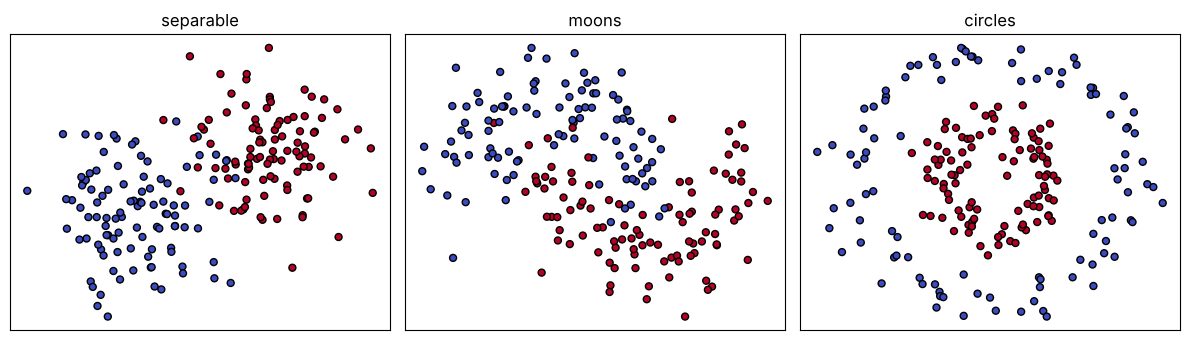

In [2]:
def make_data():
    X1, y1 = make_blobs(n_samples=200, centers=[[-2, -1], [2, 1]], cluster_std=1.2, random_state=0)
    X2, y2 = make_moons(200, noise=0.25, random_state=0)
    X3, y3 = make_circles(200, noise=0.1, factor=0.4, random_state=0)
    data = {"separable": (X1, y1), "moons": (X2, y2), "circles": (X3, y3)}
    split = {k: train_test_split(X, y, test_size=0.3, stratify=y, random_state=0) for k, (X, y) in data.items()}
    return data, split

DATA, SPLIT = make_data()

def draw(ax, model, name, title=""):
    Xtr, Xte, ytr, yte = SPLIT[name]
    mod = clone(model).fit(Xtr, ytr)
    X = DATA[name][0]
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .7, X[:, 0].max() + .7, 250),
                         np.linspace(X[:, 1].min() - .7, X[:, 1].max() + .7, 250))
    Z = mod.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap=CMAP, levels=[-.5, .5, 1.5])
    ax.scatter(*Xtr.T, c=ytr, cmap=CMAP, edgecolor="k", s=25, label="train")
    ax.scatter(*Xte.T, c=yte, cmap=CMAP, edgecolor="k", s=70, marker="s", label="test")
    acc = mod.score(Xte, yte)
    ax.set_title(f"{title} {name}: test acc = {acc:.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    return mod, acc

def model_panel(model, title=""):
    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    for ax, name in zip(axs, DATA):
        draw(ax, model, name, title)
    axs[0].legend(loc="lower left", fontsize=8)
    plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (name, (X, y)) in zip(axs, DATA.items()):
    ax.scatter(*X.T, c=y, cmap=CMAP, edgecolor="k", s=25); ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [3]:
# Helper to write notes on top of the plots (used in the deep dives)
def annot(ax, text, xy, xytext, color="k"):
    ax.annotate(text, xy=xy, xytext=xytext, fontsize=9, color=color,
                arrowprops=dict(arrowstyle="->", color=color, lw=1),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=color, alpha=.9))

# Part A. Classification

The common thread, in one line: **all these models compute a score and then decide the class**. What changes is *how* they choose the weights and *what shape* the boundary can have.

First of all the baseline (the dummy), which is not a model to beat but a **yardstick**.

## A0. Dummy classifier `[course]`

- **Idea**: completely ignores the features and always predicts the most frequent class.
- **What makes it special**: it learns nothing. It is the minimum reference: if your model does not beat it, it has learned nothing.
- **Strengths**: costs nothing, tells you what "guessing" is worth with those class proportions.
- **Weaknesses**: it is not a candidate, just the yardstick. With imbalanced classes it can have high accuracy (e.g. 95%) while being useless.

In [4]:
for name, (X, y) in DATA.items():
    Xtr, Xte, ytr, yte = SPLIT[name]
    d = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
    print(f"{name:11s} dummy test acc = {d.score(Xte, yte):.2f}   (balanced classes: we expect about 0.5)")

separable   dummy test acc = 0.50   (balanced classes: we expect about 0.5)
moons       dummy test acc = 0.50   (balanced classes: we expect about 0.5)
circles     dummy test acc = 0.50   (balanced classes: we expect about 0.5)


## A1. Perceptron `[course]`

- **Idea**: compute $z = \mathbf{w}^\top \mathbf{x}$ and apply a **threshold**: class +1 if $z\ge 0$, otherwise −1. At every mistake, move the weights towards the misclassified point.
- **What makes it special**: the error is **0 or 1** (right/wrong); it does not say "by how much" you are wrong. No probabilities.
- **Strengths**: very simple and fast. If the data are linearly separable it **converges** to a line that separates them all `[course]`.
- **Weaknesses**: if the data are **not** separable it never settles: the weights keep oscillating `[course]`. Among the infinitely many correct lines it picks any one, not the best `[mine]`.
- **Knobs**: `eta0` (learning rate), `max_iter`.

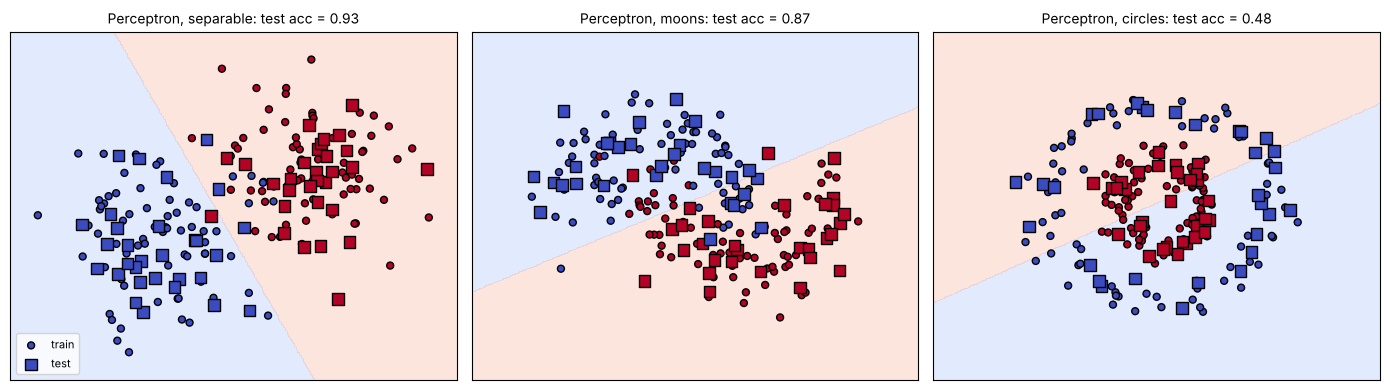

In [5]:
model_panel(make_pipeline(StandardScaler(), Perceptron(random_state=0)), "Perceptron,")

### Deep dive: Perceptron

**Why is it called that?** It comes from the McCulloch-Pitts artificial neuron (nb 02): it receives inputs $x_j$, weighs them with $w_j$, sums them into $z=\mathbf{w}^\top\mathbf{x}$ and "fires" (+1) if the sum exceeds the threshold. *Perceptron* = the machine that "perceives" and decides.

**How it learns, with numbers.** The update rule is
$$w_j \leftarrow w_j + \eta\,(y - \hat y)\,x_j$$
- $y$ = true class, $\hat y$ = predicted class, $\eta$ = learning rate.
- If the prediction is right, $y-\hat y=0$: **the weights do not change**.
- If it is wrong, $y-\hat y=\pm2$: the weights move towards the misclassified point.

Example: $\mathbf{w}=(0.2,\,-0.5)$, point $\mathbf{x}=(1,\,1)$ with true class $y=+1$, $\eta=0.1$.
1. $z = 0.2\cdot1 - 0.5\cdot1 = -0.3 < 0$, so $\hat y=-1$: **wrong**.
2. $\Delta\mathbf{w} = 0.1\cdot(1-(-1))\cdot(1,1) = (0.2,\,0.2)$.
3. New weights $\mathbf{w}=(0.4,\,-0.3)$: now $z=0.1\ge0$, so $\hat y=+1$. **Correct.**

**The key point** (nb 02, *Algorithm convergence*): if the classes can be separated by a line, the number of mistakes reaches 0 and stops. If they cannot, there is always a misclassified point, so the weights never stop changing. The plot below shows it.

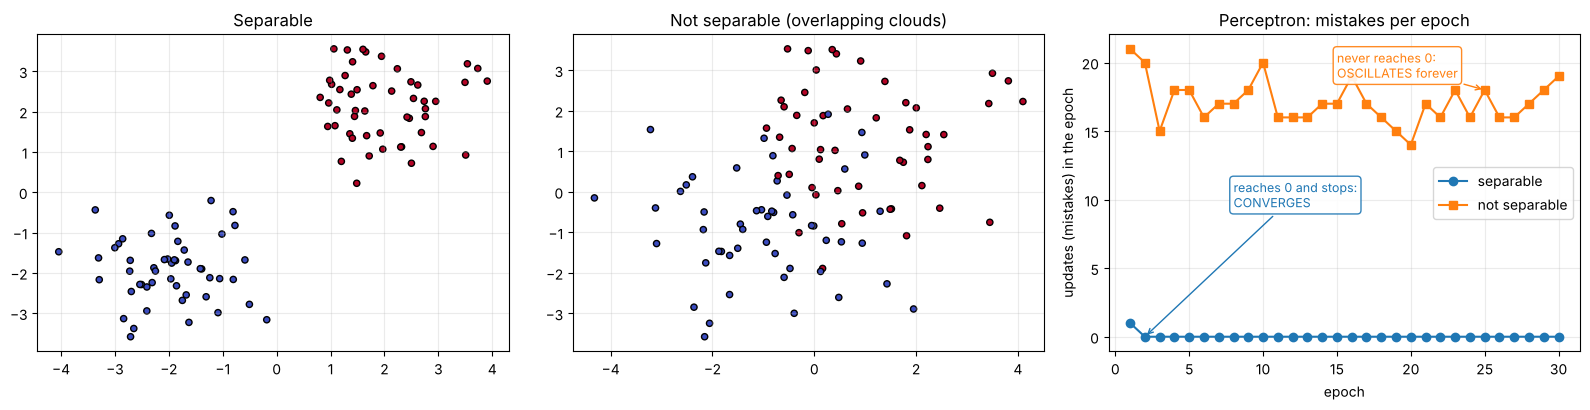

In [6]:
def perceptron_errors(X, y, eta=0.1, epochs=30, seed=1):
    rng = np.random.RandomState(seed)
    w = rng.normal(0, 0.01, X.shape[1] + 1)
    errors = []
    for _ in range(epochs):
        e = 0
        for xi, yi in zip(X, y):
            yhat = 1 if xi @ w[1:] + w[0] >= 0 else -1
            upd = eta * (yi - yhat)
            w[1:] += upd * xi; w[0] += upd
            e += int(upd != 0)
        errors.append(e)
    return errors

Xs, ys = make_blobs(100, centers=[[-2, -2], [2, 2]], cluster_std=0.8, random_state=0)
Xn, yn = make_blobs(100, centers=[[-1, -1], [1, 1]], cluster_std=1.3, random_state=0)
ys, yn = np.where(ys == 1, 1, -1), np.where(yn == 1, 1, -1)
es, en = perceptron_errors(Xs, ys), perceptron_errors(Xn, yn)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(*Xs.T, c=ys, cmap=CMAP, edgecolor="k", s=20); ax[0].set_title("Separable")
ax[1].scatter(*Xn.T, c=yn, cmap=CMAP, edgecolor="k", s=20); ax[1].set_title("Not separable (overlapping clouds)")
ax[2].plot(range(1, 31), es, "o-", label="separable"); ax[2].plot(range(1, 31), en, "s-", label="not separable")
ax[2].set_xlabel("epoch"); ax[2].set_ylabel("updates (mistakes) in the epoch"); ax[2].legend()
annot(ax[2], "reaches 0 and stops:\nCONVERGES", (2, 0), (8, max(en) * .45), "tab:blue")
annot(ax[2], "never reaches 0:\nOSCILLATES forever", (25, en[24]), (15, max(en) * .9), "tab:orange")
ax[2].set_title("Perceptron: mistakes per epoch")
plt.tight_layout(); plt.show()

**What to look at in the plot.** On the first dataset it succeeds. On moons and circles the boundary is still **a straight line**: it is the only shape it can draw, so it cannot cope.

## A2. Adaline `[course]`

- **Idea**: same $z=\mathbf{w}^\top\mathbf{x}$ as the Perceptron, but the error is computed on $z$ **itself** (linear activation), not on the threshold. It minimises the sum of squared errors.
- **What makes it special**: the error is continuous, so there is a (convex) function to minimise and you can use **gradient descent** or the **closed form** (pseudo-inverse).
- **Strengths**: always converges to a minimum (with a suitable $\eta$), even with non-separable data. Great for understanding gradient descent.
- **Weaknesses**: the squared error on ±1 labels also penalises "too correct" points (very far from the boundary) `[mine]`. Still a linear boundary. Sensitive to feature scale.
- **Knobs**: $\eta$ and number of epochs (for GD).

For this review I implement it in closed form, which for this purpose gives the same minimum as a well-converged GD `[course]`: linear regression on −1/+1 labels, then take the sign.

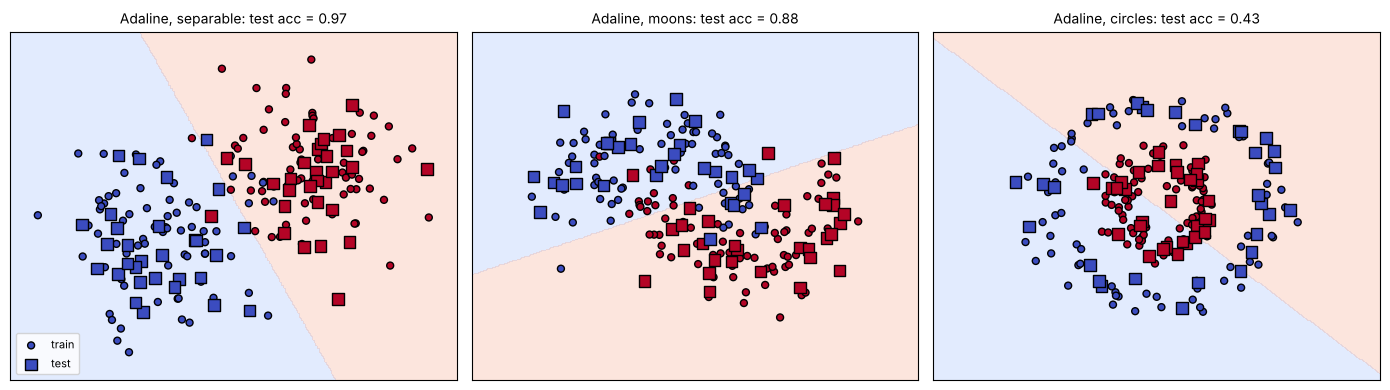

In [7]:
class AdalineCF(BaseEstimator, ClassifierMixin):
    # Adaline in closed form (least squares on y in {-1,+1}), then threshold on the sign
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        t = np.where(y == self.classes_[1], 1.0, -1.0)
        self.lin_ = LinearRegression().fit(X, t)
        return self
    def predict(self, X):
        return np.where(self.lin_.predict(X) >= 0, self.classes_[1], self.classes_[0])

model_panel(make_pipeline(StandardScaler(), AdalineCF()), "Adaline,")

### Deep dive: Adaline

**Why is it called that?** ADAptive LInear NEuron. *Linear* because the error is computed on the linear output $z$, not on the threshold.

**The difference in one line** (nb 02, *Key Difference from the Perceptron*): the Perceptron only says "right or wrong", Adaline says "**by how much**" you are wrong. That is why there is a smooth cost function to minimise:
$$J(\mathbf{w})=\frac12\sum_n \big(y_n - z_n\big)^2,\qquad z_n=\mathbf{w}^\top\mathbf{x}_n$$

**Two ways to find the minimum**
- **Closed form**: $\mathbf{w}=\mathbf{X}^{+}\mathbf{y}$ with the pseudo-inverse (nb 01, *Moore-Penrose*). One shot.
- **Gradient descent**: take small steps downhill, $\mathbf{w}\leftarrow\mathbf{w}+\eta\,\mathbf{X}^\top(\mathbf{y}-\mathbf{z})$. It is a process.

**Variants of gradient descent** (nb 02, *Large-scale learning*):
| Variant | Points used per step | Pros / cons |
|---|---|---|
| Batch GD | all $N$ | precise steps, but slow with lots of data |
| Mini-batch | a small group (e.g. 32) | compromise, the most used |
| SGD | **just one** ($m=1$) | very fast, but the cost "jumps around" |

In the plot the SGD cost is measured once per epoch, so it looks smooth: the "jumping" happens between one point and the next. The two methods use different $\eta$ because SGD takes one step per point.

**The delicate point is $\eta$**: too small and it takes forever, too large and it **diverges** (the cost explodes). And with non-standardised features a single $\eta$ is fine for one feature and terrible for another: that is why we standardise (nb 02, *Best practices*).

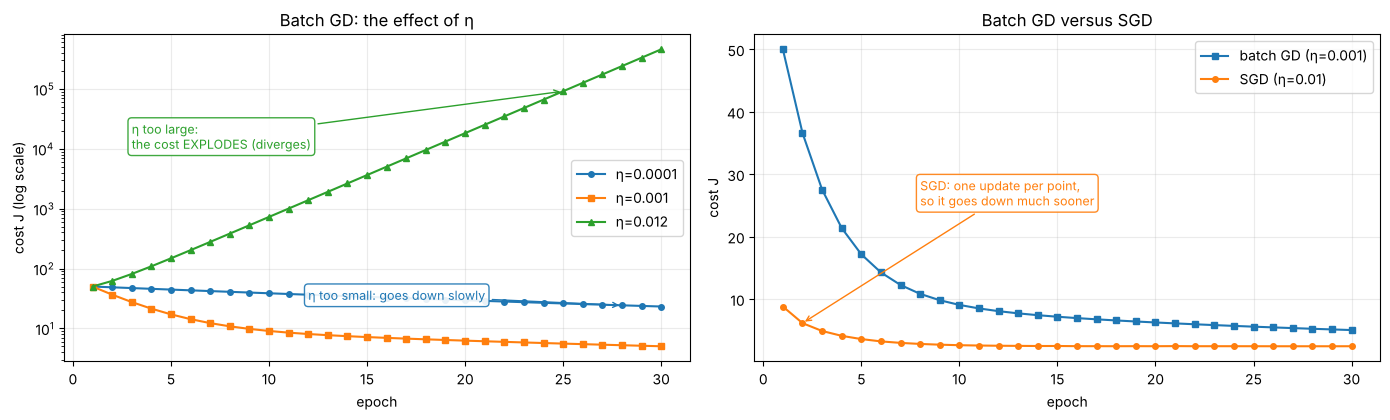

In [8]:
from sklearn.datasets import load_iris
ir = load_iris(); Xa = StandardScaler().fit_transform(ir.data[:100][:, [0, 2]])
ya = np.where(ir.target[:100] == 0, -1, 1)

def adaline_gd(X, y, eta, epochs=30):
    w = np.zeros(X.shape[1] + 1); J = []
    for _ in range(epochs):
        err = y - (X @ w[1:] + w[0])
        w[1:] += eta * X.T @ err; w[0] += eta * err.sum()
        J.append(0.5 * (err ** 2).sum())
    return J

def adaline_sgd(X, y, eta, epochs=30, seed=1):
    rng = np.random.RandomState(seed); w = np.zeros(X.shape[1] + 1); J = []
    for _ in range(epochs):
        for i in rng.permutation(len(y)):
            e = y[i] - (X[i] @ w[1:] + w[0]); w[1:] += eta * e * X[i]; w[0] += eta * e
        J.append(0.5 * ((y - (X @ w[1:] + w[0])) ** 2).sum())
    return J

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for eta, st in [(0.0001, "o-"), (0.001, "s-"), (0.012, "^-")]:
    ax[0].plot(range(1, 31), adaline_gd(Xa, ya, eta), st, ms=4, label=f"η={eta}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cost J (log scale)"); ax[0].legend()
ax[0].set_title("Batch GD: the effect of η")
annot(ax[0], "η too large:\nthe cost EXPLODES (diverges)", (25, adaline_gd(Xa, ya, 0.012)[24]), (3, 1e4), "tab:green")
annot(ax[0], "η too small: goes down slowly", (28, adaline_gd(Xa, ya, 0.0001)[27]), (12, 30), "tab:blue")
ax[1].plot(range(1, 31), adaline_gd(Xa, ya, 0.001), "s-", ms=4, label="batch GD (η=0.001)")
ax[1].plot(range(1, 31), adaline_sgd(Xa, ya, 0.01), "o-", ms=4, label="SGD (η=0.01)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cost J"); ax[1].legend(); ax[1].set_title("Batch GD versus SGD")
annot(ax[1], "SGD: one update per point,\nso it goes down much sooner", (2, adaline_sgd(Xa, ya, 0.01)[1]), (8, 25), "tab:orange")
plt.tight_layout(); plt.show()

## A3. Logistic regression `[course]`

- **Idea**: $z=\mathbf{w}^\top\mathbf{x}$, then the **sigmoid** $\sigma(z)=1/(1+e^{-z})$ turns $z$ into a **probability** of the positive class. You decide with threshold 0.5 (adjustable).
- **What makes it special**: it returns **probabilities**, so you can move the threshold to trade precision against recall. It is trained by minimising the log-loss.
- **Strengths**: the reference model to start with. Probabilities, interpretable boundary (the weights tell you which features matter), fast. Regularised by default.
- **Weaknesses**: **linear** boundary in feature space (it can be curved with `PolynomialFeatures`, as in notebook 06).
- **Knobs**: `C` = **inverse** of the regularisation (small C = more regularised, `C=np.inf` = none), L1/L2 penalty.

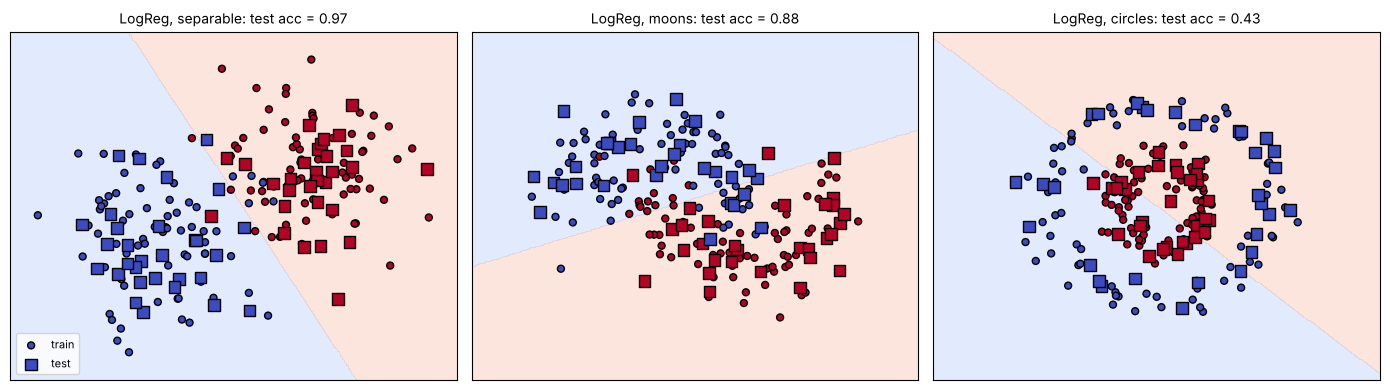

In [9]:
model_panel(make_pipeline(StandardScaler(), LogisticRegression(C=1.0)), "LogReg,")

### Deep dive: logistic regression

**Why "regression" if it classifies?** Because it first *regresses* a continuous number, the probability, and only afterwards the threshold turns it into a class.

**Where the sigmoid comes from** (nb 02, *Odds ratio and logit*):
- **Odds**: $\frac{p}{1-p}$. If $p=0.8$, the odds are $4$ ("4 to 1").
- **Logit**: $\log\frac{p}{1-p}$. It goes from $-\infty$ to $+\infty$, so it can be set equal to a line: $\log\frac{p}{1-p}=z=\mathbf{w}^\top\mathbf{x}$.
- Solving for $p$ gives the **sigmoid**: $p=\sigma(z)=\frac{1}{1+e^{-z}}$.

Values to remember: $\sigma(0)=0.5$, $\sigma(2)\approx0.88$, $\sigma(-2)\approx0.12$.

**The difference from Adaline** (nb 02, *Differences with ADALINE?*): the update formula has the same shape, but the error is $y-\sigma(z)$ instead of $y-z$, and the cost is the **log-loss** instead of the squared error.

**The practical advantage: the threshold can move.** With the probability in hand you can decide "positive if $p\ge 0.3$" instead of $0.5$. Lowering the threshold raises **recall** (you find more positives) and lowers **precision** (more false alarms). The second plot shows it.

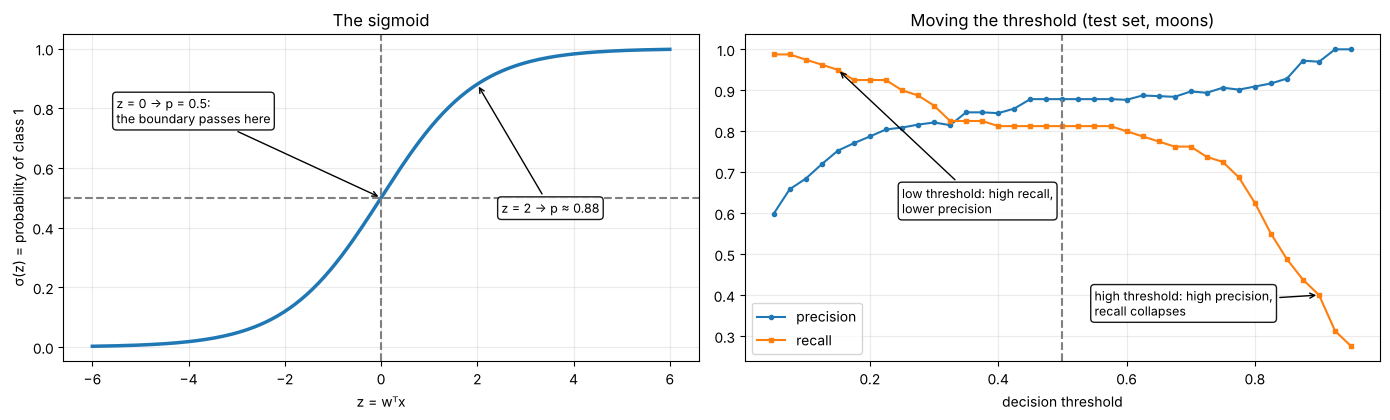

In [10]:
from sklearn.metrics import precision_score, recall_score
z = np.linspace(-6, 6, 200); sig = 1 / (1 + np.exp(-z))
Xl, yl = make_moons(400, noise=0.35, random_state=3)
Xltr, Xlte, yltr, ylte = train_test_split(Xl, yl, test_size=.4, stratify=yl, random_state=0)
lr = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xltr, yltr)
p = lr.predict_proba(Xlte)[:, 1]
thresholds = np.linspace(0.05, 0.95, 37)
P = [precision_score(ylte, p >= s, zero_division=1) for s in thresholds]
R = [recall_score(ylte, p >= s) for s in thresholds]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].plot(z, sig, lw=2.5); ax[0].axhline(.5, ls="--", c="gray"); ax[0].axvline(0, ls="--", c="gray")
ax[0].set_xlabel("z = wᵀx"); ax[0].set_ylabel("σ(z) = probability of class 1"); ax[0].set_title("The sigmoid")
annot(ax[0], "z = 0 → p = 0.5:\nthe boundary passes here", (0, .5), (-5.5, .75))
annot(ax[0], "z = 2 → p ≈ 0.88", (2, 1 / (1 + np.exp(-2))), (2.5, .45))
ax[1].plot(thresholds, P, "o-", ms=3, label="precision"); ax[1].plot(thresholds, R, "s-", ms=3, label="recall")
ax[1].axvline(.5, ls="--", c="gray"); ax[1].set_xlabel("decision threshold"); ax[1].legend()
ax[1].set_title("Moving the threshold (test set, moons)")
annot(ax[1], "low threshold: high recall,\nlower precision", (.15, R[4]), (.25, .6))
annot(ax[1], "high threshold: high precision,\nrecall collapses", (.9, R[-3]), (.55, .35))
plt.tight_layout(); plt.show()

## A3b. More than two classes `[course]` (nb 03)

The Perceptron and logistic regression are born for **two** classes. With $K$ classes there are three routes:

| Strategy | What it trains | How many models | How it decides |
|---|---|---|---|
| **One-vs-Rest (OvR)** | "class $k$ against all the others" | $K$ | the highest score wins |
| **One-vs-One (OvO)** | every pair of classes | $K(K-1)/2$ | **vote** among the pairs (ties possible, nb 03) |
| **Native** (multinomial logistic, LDA, k-NN) | a single model | 1 | a probability for each class |

**Softmax** (multinomial logistic): turns $K$ scores into $K$ probabilities that sum to 1:
$$p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}$$
Example with $z=(2,\,1,\,0)$: $e^2\approx7.39$, $e^1\approx2.72$, $e^0=1$, sum $\approx11.11$, so $p\approx(0.665,\ 0.245,\ 0.090)$. Class 1 wins, and you also know **how** confident it is.

Labels for the softmax are written in **one-hot**: class 2 of 3 becomes $(0,1,0)$.

**Connection**: `SVC` uses OvO internally (sklearn page 1.4), `LogisticRegression` is natively multinomial.

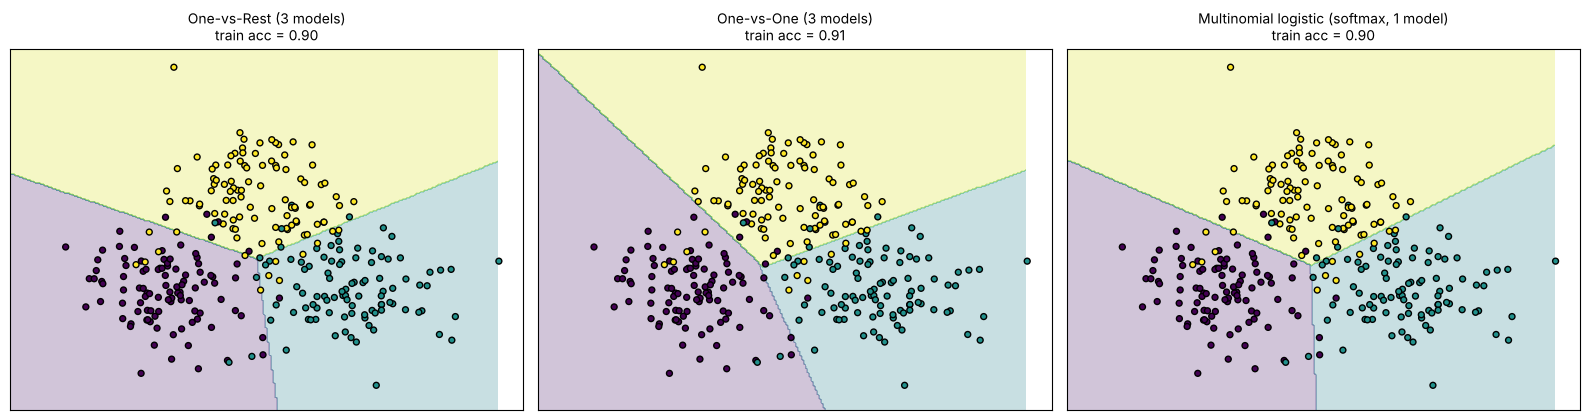

softmax of (2,1,0): [0.665 0.245 0.09 ]


In [11]:
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
X3, y3 = make_blobs(300, centers=[[-2, 0], [2, 0], [0, 2.5]], cluster_std=1.0, random_state=1)
strategies = {
    "One-vs-Rest (3 models)": OneVsRestClassifier(make_pipeline(StandardScaler(), Perceptron(random_state=0))),
    "One-vs-One (3 models)": OneVsOneClassifier(make_pipeline(StandardScaler(), Perceptron(random_state=0))),
    "Multinomial logistic (softmax, 1 model)": make_pipeline(StandardScaler(), LogisticRegression()),
}
xx, yy = np.meshgrid(np.linspace(-5, 5, 250), np.linspace(-3.5, 7, 250))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, (nm, m) in zip(ax, strategies.items()):
    m.fit(X3, y3)
    a.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=.25, cmap="viridis")
    a.scatter(*X3.T, c=y3, cmap="viridis", edgecolor="k", s=18)
    a.set_title(f"{nm}\ntrain acc = {m.score(X3, y3):.2f}", fontsize=10); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
zz = np.array([2., 1., 0.]); print("softmax of (2,1,0):", (np.exp(zz) / np.exp(zz).sum()).round(3))

## A3c. Feature mapping: bending a linear model `[course]` (nb 04, *Kernels* slides)

**Idea**: if the boundary in the original space is curved, **add columns** (for example $x_1^2$, $x_2^2$, $x_1x_2$) and use the same linear model in the new space. In the new space the boundary is a plane; in the old one it becomes a curve.

Example from the slides: for the circles $\phi(\mathbf{x})=(x_1,\,x_2,\,x_1^2+x_2^2)$ is enough. The third coordinate is the **squared radius**: the inner circle has a small radius, the outer one a large radius, so a threshold on $r^2$ separates them.

**The price**: the number of columns explodes with the degree (see the table in Part B, *curse of dimensionality*). That is why **kernels** exist: they do the same thing without building the columns.

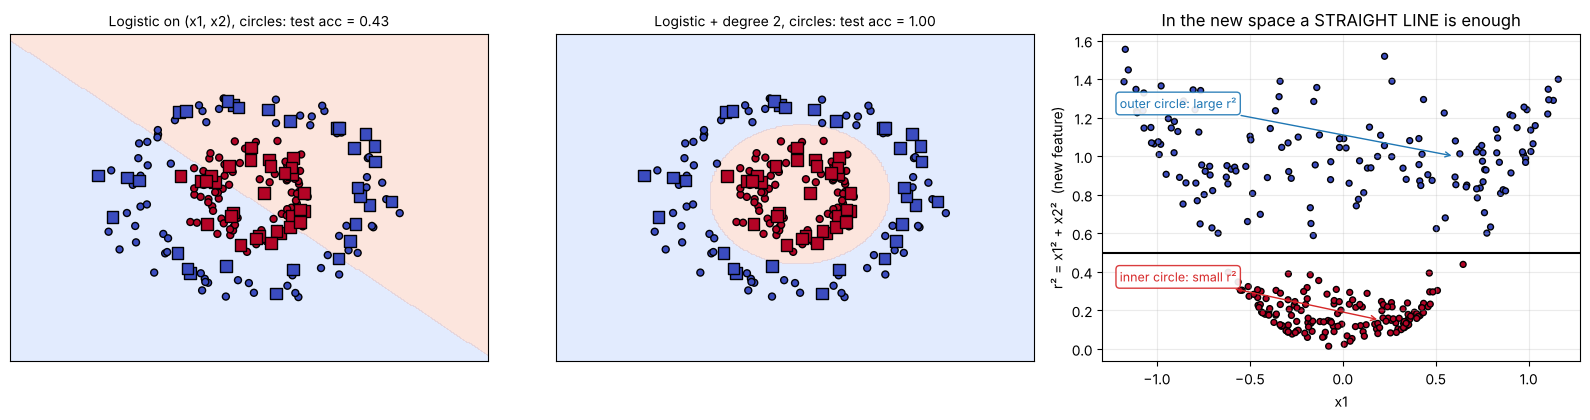

In [12]:
Xc2, yc2 = make_circles(300, noise=0.1, factor=0.4, random_state=0)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
draw(ax[0], make_pipeline(StandardScaler(), LogisticRegression()), "circles", "Logistic on (x1, x2),")
draw(ax[1], make_pipeline(PolynomialFeatures(2), StandardScaler(), LogisticRegression()), "circles", "Logistic + degree 2,")
r2 = (Xc2 ** 2).sum(1)
ax[2].scatter(Xc2[:, 0], r2, c=yc2, cmap=CMAP, edgecolor="k", s=18)
ax[2].axhline(0.5, c="k", lw=1.5); ax[2].set_xlabel("x1"); ax[2].set_ylabel("r² = x1² + x2²  (new feature)")
ax[2].set_title("In the new space a STRAIGHT LINE is enough")
annot(ax[2], "outer circle: large r²", (0.6, 1.0), (-1.2, 1.25), "tab:blue")
annot(ax[2], "inner circle: small r²", (0.2, 0.15), (-1.2, 0.35), "tab:red")
plt.tight_layout(); plt.show()

**Try it yourself.** Change `C` to `0.001` and to `1000` and see how the slope of the line changes (not the shape: it stays a line).

**Perceptron, Adaline and logistic in one sentence**: same $z=\mathbf{w}^\top\mathbf{x}$, three different ways of *measuring the error*: threshold error (0/1), squared error on $z$, log-loss on $\sigma(z)$.

## A4. Linear SVM `[course]`

- **Idea**: among all the lines that separate the data, choose the one with the **maximum margin** (the widest strip with no points inside, of width $2/\|\mathbf{w}\|$). * Margin = space between the line to the first vector, larger it is better the algorithm is working
- **What makes it special**: the boundary depends **only on the support vectors**, i.e. the few points that touch the margin. The others can be deleted without changing anything.
- **Strengths**: a "well-defined" choice among infinitely many lines (unlike the Perceptron). Very good generalisation with high-dimensional data.
- **Weaknesses**: no direct probabilities. `SVC` is slow with tens of thousands of rows `[course]`/sklearn. Linear.
- **Knobs**: `C` (soft margin: large C = little tolerance for errors, narrow margin; small C = wide margin).
Whats a vector, a vector V is about the feature of our Matrix in input.
Why stands for Support vectors? Because we consider the margin line the one that is not fully dotted like a bridge and we consider the vectors inside the margin and on the margin line like the columns that supports this margin, if we move our support vectors outside the margin it falls and it moves also.
This algorithm take in input also an Hyperparameter C and it can change a lot about the margin (smaller or larger)

> **Tutor's note on your English notes.** The idea of the bridge and its pillars is right. Three small clarifications:
> 1. *"a vector V is about the feature of our Matrix"*: here a **vector is a point**, i.e. **one row** of the matrix with all its features (one training example), not a column.
> 2. *"the margin line the one that is not fully dotted"*: the **solid** line is the **decision boundary**; the two **dashed** lines are the **edges of the margin**. Support vectors lie on the dashed lines, inside the strip, or on the wrong side.
> 3. *"larger it is better the algorithm is working"*: a wide margin usually generalises better, but with a small `C` you get it **by accepting more errors** on the training set. It is a trade-off to choose with cross-validation, not "wider = always better".

## How many support vectors? Few or many

A **support vector** is a training point that lies on the edge of the margin, inside the margin, or on the wrong side. The boundary depends **only on these points**: if you remove a distant point, the boundary does not change.

The number of support vectors **is not a goal**, it is a symptom. Read it together with train and test accuracy:

| Situation | Support vectors | What it means |
|---|---|---|
| Separable data, high `C` | few | clean problem, simple model, fast prediction |
| Small `C` | many | wide margin, more regularised (more bias, less variance) |
| Overlapping classes | many | hard data, no clean margin |
| RBF with very high `gamma` | almost all | overfitting: high train, low test |

To choose `C` and `gamma` you **don't** count support vectors: you use the validation curve or GridSearchCV.

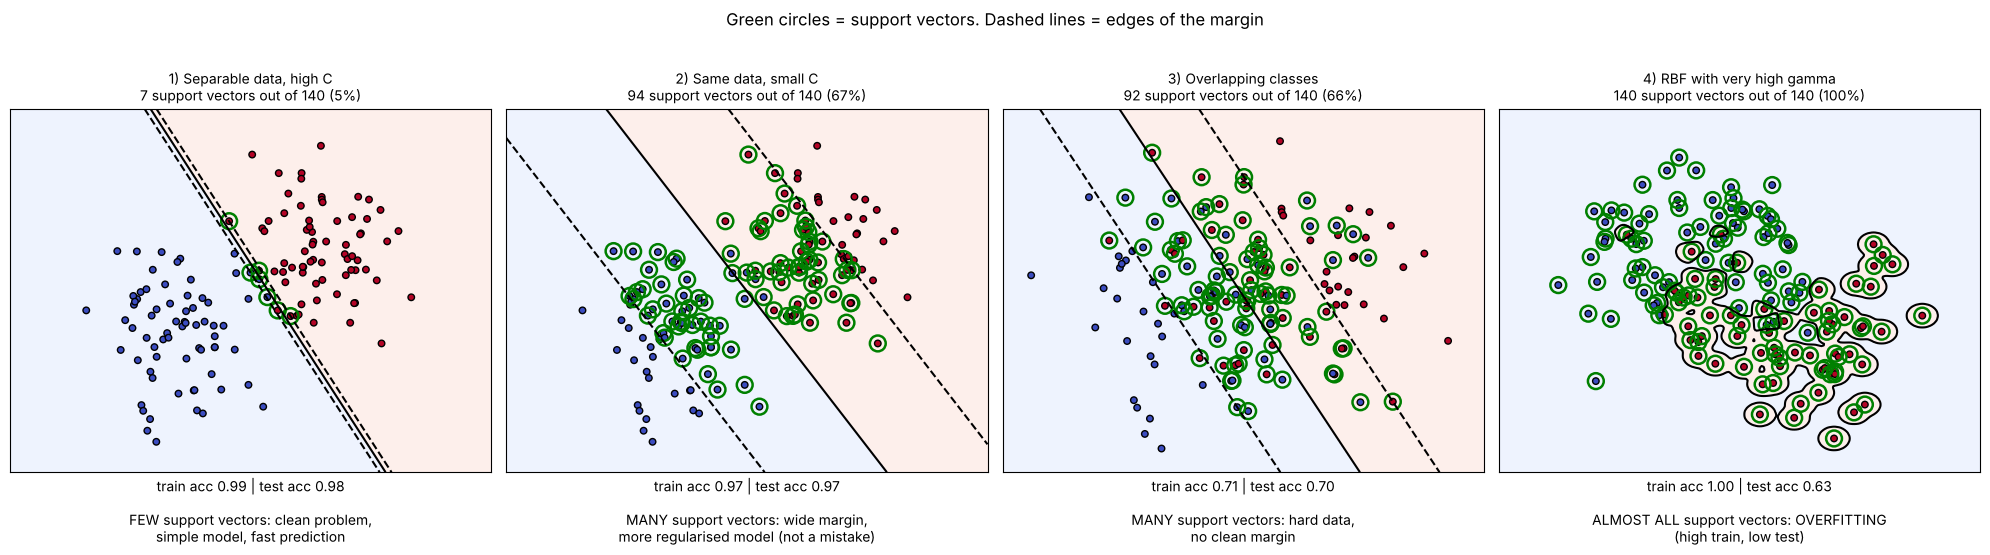

In [13]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

cases = [
    ("1) Separable data, high C", make_blobs(200, centers=[[-2,-1],[2,1]], cluster_std=1.0, random_state=0),
     SVC(kernel="linear", C=100), "FEW support vectors: clean problem,\nsimple model, fast prediction"),
    ("2) Same data, small C", make_blobs(200, centers=[[-2,-1],[2,1]], cluster_std=1.0, random_state=0),
     SVC(kernel="linear", C=0.01), "MANY support vectors: wide margin,\nmore regularised model (not a mistake)"),
    ("3) Overlapping classes", make_blobs(200, centers=[[-1,-0.5],[1,0.5]], cluster_std=1.6, random_state=0),
     SVC(kernel="linear", C=1), "MANY support vectors: hard data,\nno clean margin"),
    ("4) RBF with very high gamma", make_moons(200, noise=0.3, random_state=0),
     SVC(kernel="rbf", C=1, gamma=100), "ALMOST ALL support vectors: OVERFITTING\n(high train, low test)"),
]

fig, axs = plt.subplots(1, 4, figsize=(20, 5.4))
for ax, (title, (X, y), svm, caption) in zip(axs, cases):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    svm.fit(Xtr_s, ytr)
    xx, yy = np.meshgrid(np.linspace(-3, 3, 250), np.linspace(-3, 3, 250))
    D = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, D > 0, alpha=.15, cmap="coolwarm")
    ax.contour(xx, yy, D, levels=[0], colors="k")
    if svm.kernel == "linear":
        ax.contour(xx, yy, D, levels=[-1, 1], colors="k", linestyles="--")
    ax.scatter(*Xtr_s.T, c=ytr, cmap="coolwarm", edgecolor="k", s=22)
    ax.scatter(*svm.support_vectors_.T, s=130, facecolors="none", edgecolors="g", linewidths=1.8)
    n_sv, n = len(svm.support_vectors_), len(Xtr_s)
    ax.set_title(f"{title}\n{n_sv} support vectors out of {n} ({100*n_sv/n:.0f}%)", fontsize=10)
    ax.set_xlabel(f"train acc {svm.score(Xtr_s, ytr):.2f} | test acc {svm.score(Xte_s, yte):.2f}\n\n{caption}", fontsize=10)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Green circles = support vectors. Dashed lines = edges of the margin", y=1.02)
plt.tight_layout(); plt.show()

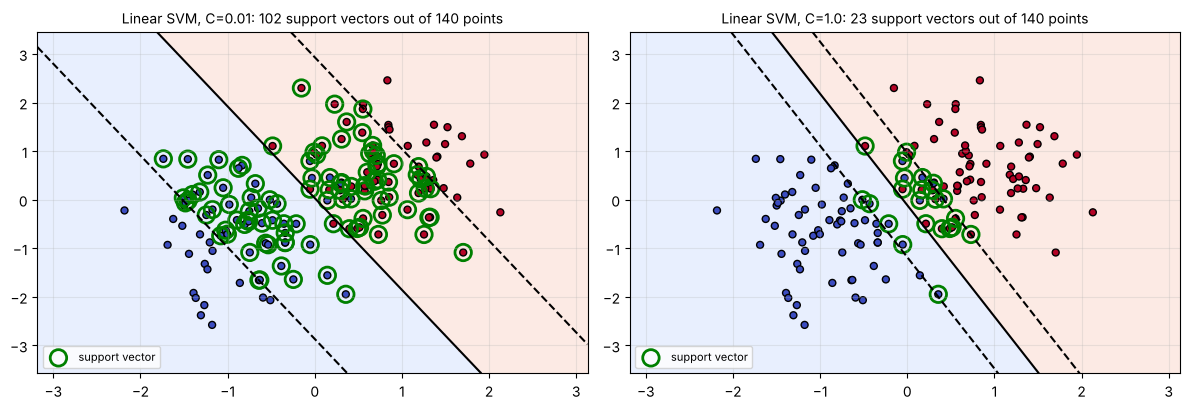

In [14]:
svm_lin = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
Xtr, Xte, ytr, yte = SPLIT["separable"]
for a, C in zip(ax, [0.01, 1.0]):
    mod = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)).fit(Xtr, ytr)
    sc, svc = mod[0], mod[1]
    Xs = sc.transform(Xtr)
    xx, yy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 200),
                         np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 200))
    D = svc.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, D > 0, alpha=.2, cmap=CMAP)
    a.contour(xx, yy, D, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    a.scatter(*Xs.T, c=ytr, cmap=CMAP, edgecolor="k", s=25)
    a.scatter(*svc.support_vectors_.T, s=140, facecolors="none", edgecolors="g", linewidths=2, label="support vector")
    a.set_title(f"Linear SVM, C={C}: {len(svc.support_vectors_)} support vectors out of {len(Xs)} points", fontsize=10)
    a.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**What to look at.** The dashed lines are the edges of the margin, the solid line is the boundary. With **small C** the margin is wide and there are many support vectors (it tolerates errors inside the margin). With **large C** the margin narrows and the support vectors become few.

## A5. Kernel SVM (RBF) `[course]`

- **Idea**: same SVM, but instead of the dot product it uses a **kernel** function. The RBF kernel measures the similarity $\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$ and allows **curved** boundaries without building the features by hand (*kernel trick*).
- **What makes it special**: every support vector acts as a "centre": the model **adapts to the data**, it has no fixed centres chosen by hand `[course]` (nb 08: *"Gaussian Kernel is not the same as Gaussian features"*).
- **Strengths**: very flexible boundaries with few knobs. Works well on medium-sized datasets.
- **Weaknesses**: slow with many samples, **does not scale well**. Very sensitive to `gamma` and `C`: overdo it and it **overfits**. Hard to interpret.
- **Knobs**: `gamma` (radius of influence of each point: large = jagged boundary), `C`.

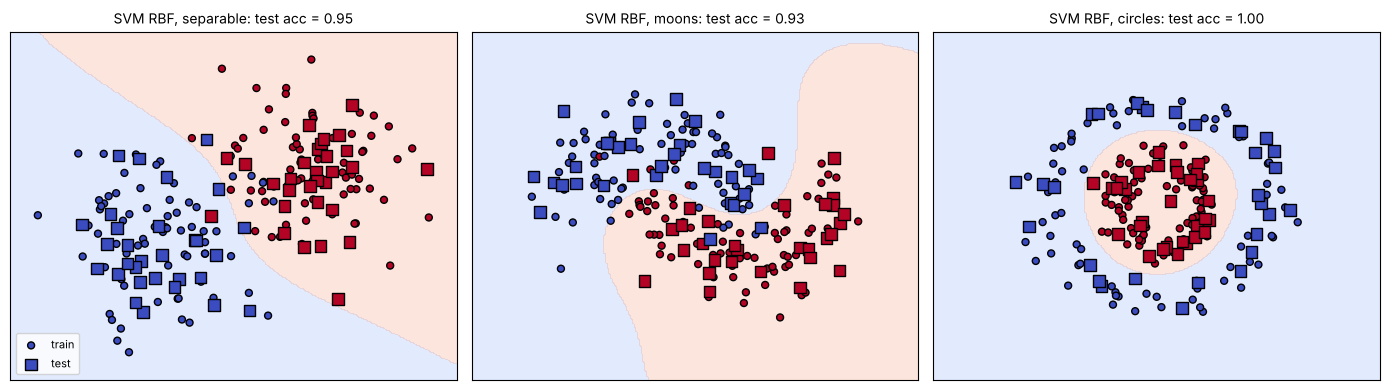

In [15]:
model_panel(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")), "SVM RBF,")

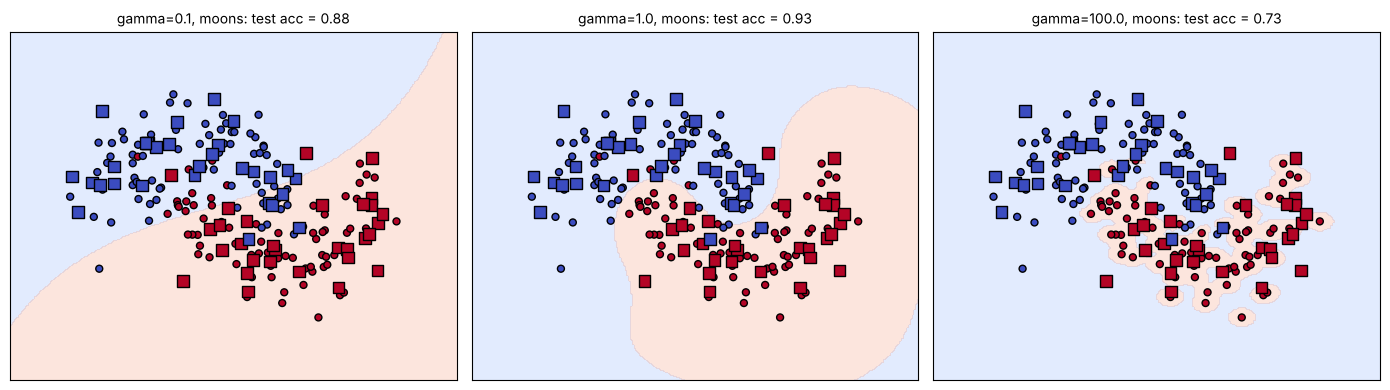

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, g in zip(axs, [0.1, 1.0, 100.0]):
    draw(ax, make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma=g)), "moons", f"gamma={g},")
plt.tight_layout(); plt.show()

**What to look at.** Small `gamma` = almost straight boundary (underfitting), right `gamma` = reasonable boundary, `gamma=100` = islands around single points (overfitting). Also check the test accuracy: it drops when the boundary "learns by heart".

### Deep dive: kernels and the RBF SVM (*Kernels and Non-Parametric Models* slides)

**What is a kernel?** A function $k(\mathbf{x},\mathbf{z})$ that gives a **similarity number** between two points. Formally it is a dot product in a feature space: $k(\mathbf{x},\mathbf{z})=\phi(\mathbf{x})^\top\phi(\mathbf{z})$.

| Kernel | Formula | Intuition |
|---|---|---|
| Linear | $\mathbf{x}^\top\mathbf{z}$ | cosine of the angle × lengths |
| Polynomial | $(\mathbf{x}^\top\mathbf{z}+c)^p$ | like `PolynomialFeatures` of degree $p$ |
| RBF / Gaussian | $\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$ | 1 if the points coincide, towards 0 if they are far apart |

**The kernel trick**: if an algorithm uses the data **only through dot products**, you can replace them with $k$ and work in a huge space (for RBF, infinite) without building it. It works for the SVM, but also for the **kernel perceptron**, **kernel ridge regression** and **kernel PCA** (same slides).

**How the kernel SVM predicts** (slide *Prediction with a kernel SVM*):
$$f(\mathbf{x})=\sum_{n\in S}\alpha_n t_n\, k(\mathbf{x}_n,\mathbf{x})+w_0$$
A sum of "similarities" with **only the support vectors** $S$. That is why it is **non-parametric**: more support vectors, more terms, more memory and slowness.

**`gamma` in one sentence**: how fast the similarity drops with distance. It is also written $\gamma=\frac{1}{2\sigma^2}$, with $\sigma$ = "radius of influence". You see it below.

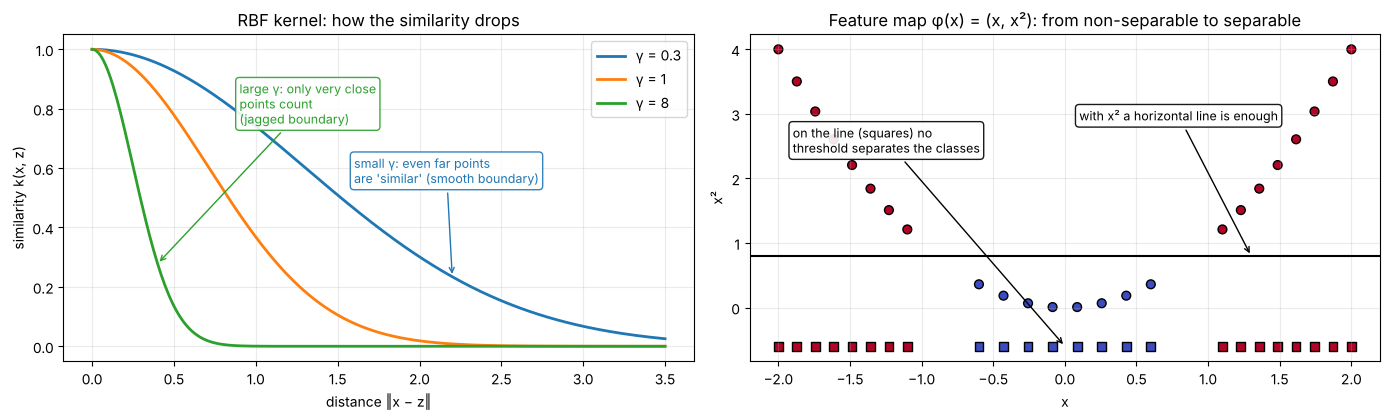

In [17]:
d = np.linspace(0, 3.5, 300)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for g in [0.3, 1, 8]:
    ax[0].plot(d, np.exp(-g * d ** 2), lw=2, label=f"γ = {g}")
ax[0].set_xlabel("distance ‖x − z‖"); ax[0].set_ylabel("similarity k(x, z)"); ax[0].legend()
ax[0].set_title("RBF kernel: how the similarity drops")
annot(ax[0], "large γ: only very close\npoints count\n(jagged boundary)", (0.4, np.exp(-8 * .16)), (0.9, .75), "tab:green")
annot(ax[0], "small γ: even far points\nare 'similar' (smooth boundary)", (2.2, np.exp(-.3 * 2.2 ** 2)), (1.6, .55), "tab:blue")
x1 = np.r_[np.linspace(-2, -1.1, 8), np.linspace(-.6, .6, 8), np.linspace(1.1, 2, 8)]
t1 = np.r_[np.ones(8), -np.ones(8), np.ones(8)]
ax[1].scatter(x1, x1 ** 2, c=t1, cmap=CMAP, edgecolor="k", s=40); ax[1].scatter(x1, np.zeros_like(x1) - .6, c=t1, cmap=CMAP, edgecolor="k", s=40, marker="s")
ax[1].axhline(0.8, c="k"); ax[1].set_xlabel("x"); ax[1].set_ylabel("x²")
ax[1].set_title("Feature map φ(x) = (x, x²): from non-separable to separable")
annot(ax[1], "on the line (squares) no\nthreshold separates the classes", (0, -.6), (-1.9, 2.4))
annot(ax[1], "with x² a horizontal line is enough", (1.3, .8), (.1, 2.9))
plt.tight_layout(); plt.show()

## A6. k-NN `[course]`

- **Idea**: to classify a point, look at the **K closest training points** and vote.
- **What makes it special**: **there is no training** and **no weights**: the model *is* the dataset. A **non-parametric** model: complexity grows with the data `[course]`.
- **Strengths**: very simple, immediate extension to many classes, boundaries of any shape, works with **any distance** (even custom ones, see the DNA exercise) `[course]`.
- **Weaknesses**: must keep **the whole** training set in memory and **every prediction is slow** `[course]`. Sensitive to feature scale and to useless features. With many dimensions distances lose meaning `[mine]`.
- **Knobs**: `n_neighbors` = K, which acts as **regularisation**: larger K, smoother boundary `[course]`. Also the metric.

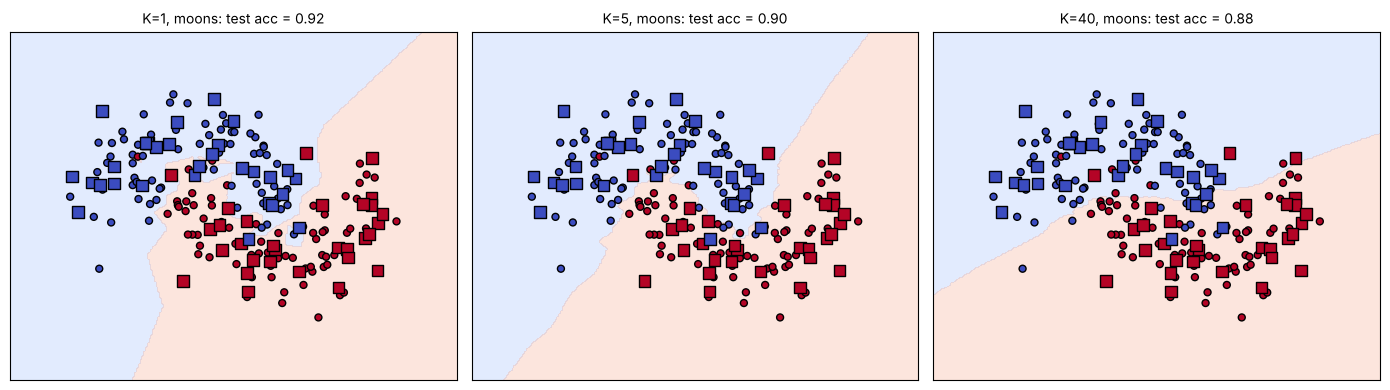

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axs, [1, 5, 40]):
    draw(ax, make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), "moons", f"K={k},")
plt.tight_layout(); plt.show()

**What to look at.** `K=1` learns every single point by heart (jagged boundary, overfitting). `K=40` is too smooth (underfitting). It is the same idea as `gamma` in the SVM or `C` in the logistic: **a knob that doses complexity**.

### Deep dive: k-NN (nb 04, nb 08, *Nearest Neighbors* slides, sklearn 1.6)

**What it receives and what it returns.** You have `X_train` with its `y_train`. A **new row** $\mathbf{x}$ arrives, **without a target**. Three steps:
1. compute the distance from $\mathbf{x}$ to **every** training row;
2. take the $K$ closest rows;
3. look at **their targets** and vote (classification) or average them (regression).

`fit` computes nothing: it just **stores** the data. All the work happens in `predict`.

**The knobs**
- `n_neighbors` = $K$: small = jagged boundary (overfitting), large = smooth (underfitting).
- `weights`: `'uniform'` (each neighbour counts 1) or `'distance'` (weight $1/d$: closer ones count more, and ties become almost impossible).
- `metric`: Euclidean $\sqrt{\sum_j (x_j-z_j)^2}$, Manhattan $\sum_j|x_j-z_j|$, or a custom distance (DNA exercise in nb 08).
- `algorithm` (`brute`, `kd_tree`, `ball_tree`, `auto`): changes **only the speed** of the search, not the result.

**Odd K?** With **two** classes it avoids ties in the vote. With three or more classes it is not enough. The value of $K$ is chosen with cross-validation anyway.

**Why is there no "starting point"?** Because there is no iterative training: no random initial weights. With the same data, $K$ and distance, the result is always the same.

**The dimensionality problem** (slide *Curse of dimensionality for KNN*): with $N$ points spread uniformly in $[0,1]^D$, the $K$ neighbours lie in a cube of side about
$$\ell \approx \left(\tfrac{K}{N}\right)^{1/D}$$
With $N=1000$ and $K=10$: in 1D $\ell=0.01$ (very close), in 10D $\ell\approx0.63$ (the "neighbourhood" covers more than half of each axis!). The neighbours **are no longer near**. The second plot shows it.

,x1,x2,y,"distance from (3, 1.5)",rank
0,1,1,A,2.06,2
1,2,1,A,1.12,1
2,4,4,B,2.69,3
3,5,4,B,3.20,4
4,5,5,B,4.03,5


K=1: neighbours = ['A']  ->  prediction A
K=3: neighbours = ['A', 'A', 'B']  ->  prediction A
K=5: neighbours = ['A', 'A', 'B', 'B', 'B']  ->  prediction B


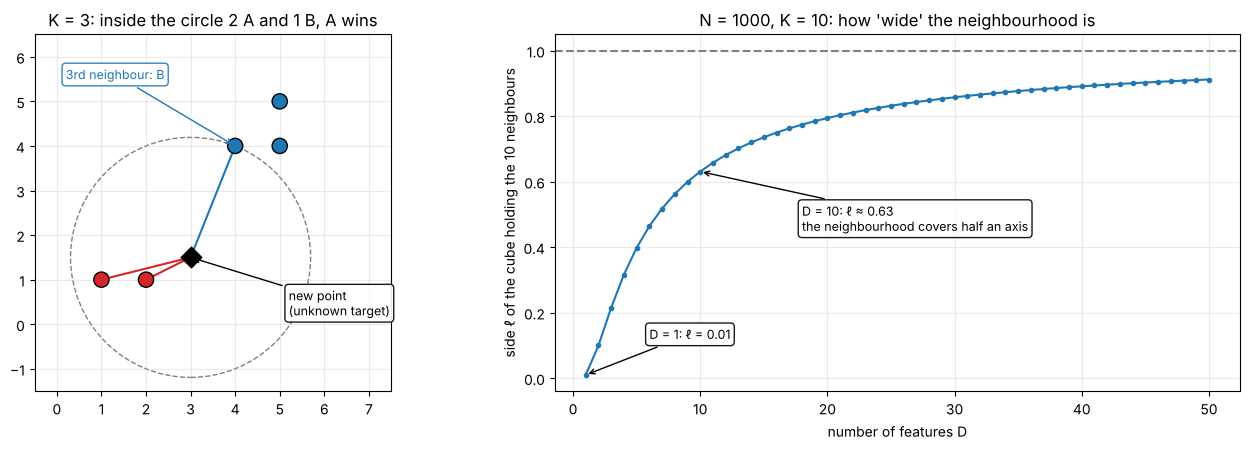

In [19]:
Xk = np.array([[1, 1], [2, 1], [4, 4], [5, 4], [5, 5]]); yk = np.array(["A", "A", "B", "B", "B"])
q = np.array([3, 1.5]); dist = np.sqrt(((Xk - q) ** 2).sum(1))
tab_knn = pd.DataFrame({"x1": Xk[:, 0], "x2": Xk[:, 1], "y": yk, "distance from (3, 1.5)": dist.round(2)})
tab_knn["rank"] = tab_knn["distance from (3, 1.5)"].rank().astype(int)
display(tab_knn)
for K in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=K).fit(Xk, yk)
    print(f"K={K}: neighbours = {[str(v) for v in yk[np.argsort(dist)[:K]]]}  ->  prediction {knn.predict([q])[0]}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
col = np.where(yk == "A", "tab:red", "tab:blue")
ax[0].scatter(*Xk.T, c=col, s=120, edgecolor="k", zorder=3); ax[0].scatter(*q, marker="D", c="k", s=110, zorder=4)
r3 = np.sort(dist)[2]
ax[0].add_patch(plt.Circle(q, r3, fill=False, ls="--", color="gray"))
for i in np.argsort(dist)[:3]:
    ax[0].plot([q[0], Xk[i, 0]], [q[1], Xk[i, 1]], c=col[i], lw=1.5)
ax[0].set_aspect("equal"); ax[0].set_xlim(-0.5, 7.5); ax[0].set_ylim(-1.5, 6.5)
ax[0].set_title("K = 3: inside the circle 2 A and 1 B, A wins")
annot(ax[0], "new point\n(unknown target)", tuple(q), (5.2, 0.2))
annot(ax[0], "3rd neighbour: B", (4, 4), (0.2, 5.5), "tab:blue")
Ds = np.arange(1, 51); ell = (10 / 1000) ** (1 / Ds)
ax[1].plot(Ds, ell, "o-", ms=3); ax[1].axhline(1, ls="--", c="gray")
ax[1].set_xlabel("number of features D"); ax[1].set_ylabel("side ℓ of the cube holding the 10 neighbours")
ax[1].set_title("N = 1000, K = 10: how 'wide' the neighbourhood is")
annot(ax[1], f"D = 10: ℓ ≈ {ell[9]:.2f}\nthe neighbourhood covers half an axis", (10, ell[9]), (18, .45))
annot(ax[1], "D = 1: ℓ = 0.01", (1, ell[0]), (6, .12))
plt.tight_layout(); plt.show()

## A7. LDA as a classifier `[mine]` + `[course]` for the reduction part

- **Idea**: assumes each class is a Gaussian cloud with the **same covariance**; the resulting boundary is a line/hyperplane `[mine]`.
- **What makes it special**: it is both a classifier and (above all in the course) a **supervised dimensionality reduction** method: it looks for the direction that maximises the **Fisher score**, i.e. separates the class means and shrinks the variance within each class `[course]` (nb 09).
- **Strengths**: fast, no knob to tune, reduces to **at most C−1 dimensions** `[course]`.
- **Weaknesses**: linear boundary; the Gaussian, shared-covariance assumption may not hold `[mine]`.
- **Knobs**: `n_components` (as a reduction), `solver`.

Its use in the project is Part B (reduction). Here we see it as a classifier for comparison.

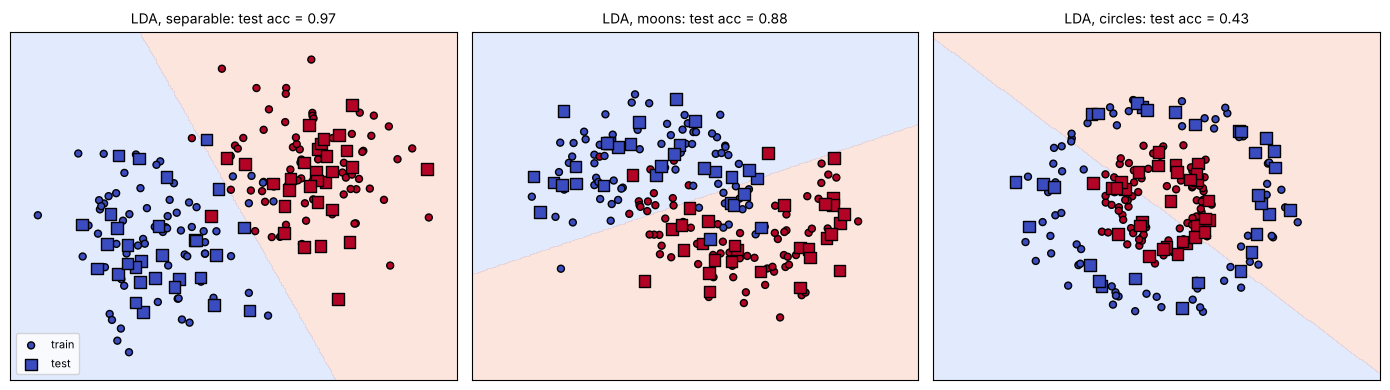

In [20]:
model_panel(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), "LDA,")

### Deep dive: LDA (and QDA) as classifiers (sklearn 1.2, nb 09)

**What is a "Gaussian cloud"?** The points of a class gather around a **centre** (mean $\boldsymbol\mu$) and thin out as you move away, with an oval shape described by the **covariance** $\Sigma$ (how wide it is in each direction and whether it is tilted). In 1D it is the bell curve.

**How it classifies**: it describes each class as a Gaussian cloud and assigns the new point to the cloud it "resembles" most (a **generative** model: it models $P(\mathbf{x}\mid y)$).
- **LDA**: all classes have **the same shape** $\Sigma$, only the centre changes: the boundary is a **line**.
- **QDA**: each class has **its own shape** $\Sigma_k$: the boundary is a **curve** (quadratic). QDA does not appear in the professor's notebooks; I mention it only for comparison `[mine]`. In the plot below a small class sits inside a large one: no line can separate them, QDA's curve can.

**What does it add compared with the Perceptron and logistic regression?**

| | Perceptron | Logistic | LDA |
|---|---|---|---|
| Output | class | class and probability | class and probability |
| Training | iterative | iterative | closed form (means and covariances) |
| Assumptions on the data | none | none | Gaussian classes, same shape |
| Multiclass | OvR/OvO | native (softmax) | native |
| **Reduces dimensions** | no | no | **yes, using the labels** (Part B) |

If the Gaussian assumption holds, LDA works well even with little data; if it does not, the logistic is more robust `[mine]`. The real "extra" for the project is dimensionality reduction.

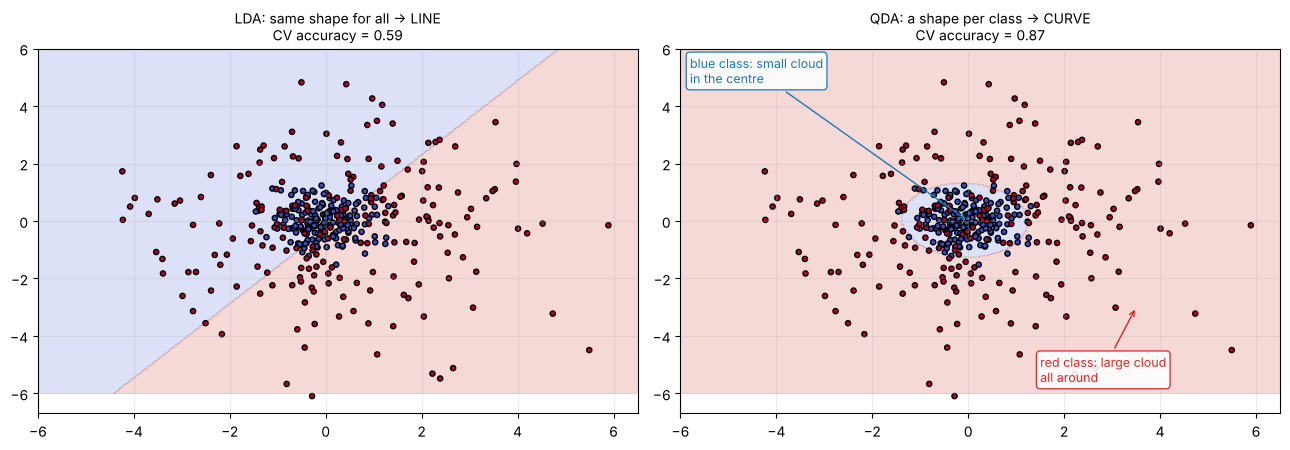

In [21]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
rng = np.random.RandomState(0)
A = rng.multivariate_normal([0, 0], [[0.3, 0], [0, 0.3]], 200)
B = rng.multivariate_normal([0.5, 0], [[4, 0], [0, 4]], 200)
Xq = np.r_[A, B]; yq = np.r_[np.zeros(200), np.ones(200)]
xx, yy = np.meshgrid(np.linspace(-6, 6.5, 300), np.linspace(-6, 6, 300))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, m, t in [(ax[0], LinearDiscriminantAnalysis(), "LDA: same shape for all → LINE"),
                (ax[1], QuadraticDiscriminantAnalysis(), "QDA: a shape per class → CURVE")]:
    m.fit(Xq, yq)
    a.contourf(xx, yy, m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=.2, cmap=CMAP)
    a.scatter(*Xq.T, c=yq, cmap=CMAP, edgecolor="k", s=14)
    a.set_title(f"{t}\nCV accuracy = {cross_val_score(m, Xq, yq, cv=5).mean():.2f}", fontsize=10)
annot(ax[1], "blue class: small cloud\nin the centre", (0, 0), (-5.8, 4.8), "tab:blue")
annot(ax[1], "red class: large cloud\nall around", (3.5, -3), (1.5, -5.6), "tab:red")
plt.tight_layout(); plt.show()

## A8. Comparison: all models on the same data

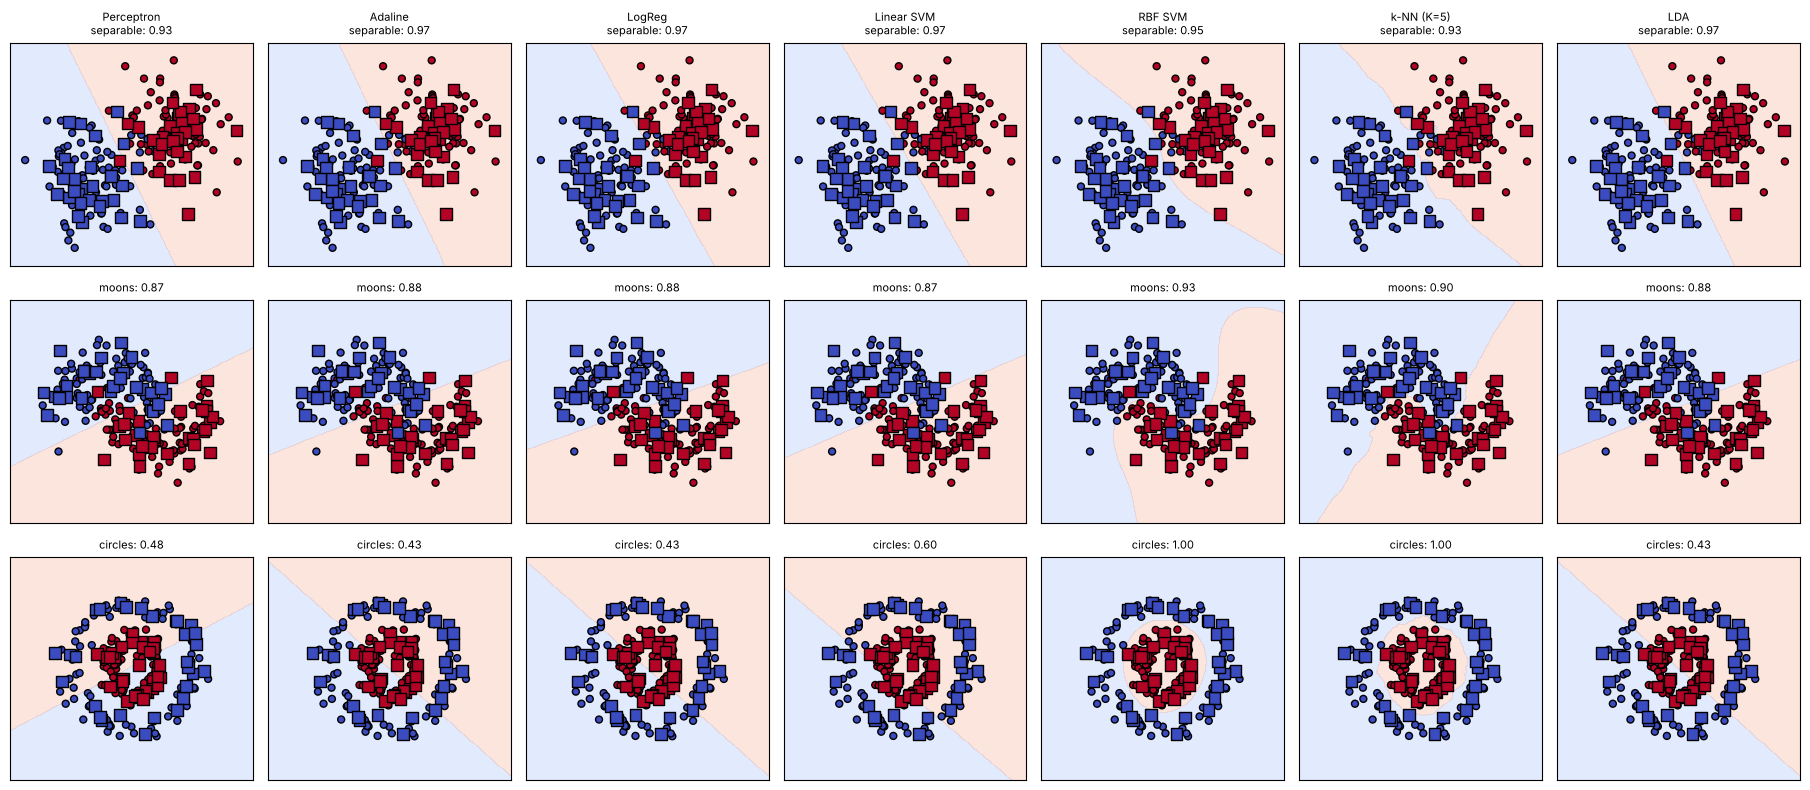

,separable,moons,circles
Perceptron,0.93,0.87,0.48
Adaline,0.97,0.88,0.43
LogReg,0.97,0.88,0.43
Linear SVM,0.97,0.87,0.60
RBF SVM,0.95,0.93,1.00
k-NN (K=5),0.93,0.90,1.00
LDA,0.97,0.88,0.43


In [22]:
MODELS = {
    "Perceptron": make_pipeline(StandardScaler(), Perceptron(random_state=0)),
    "Adaline": make_pipeline(StandardScaler(), AdalineCF()),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression()),
    "Linear SVM": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "RBF SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "k-NN (K=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
}
fig, axs = plt.subplots(3, len(MODELS), figsize=(2.6 * len(MODELS), 8))
tab = {}
for j, (nm, mod) in enumerate(MODELS.items()):
    for i, name in enumerate(DATA):
        _, acc = draw(axs[i, j], mod, name, "")
        axs[i, j].set_title(f"{nm}\n{name}: {acc:.2f}" if i == 0 else f"{name}: {acc:.2f}", fontsize=8)
        tab.setdefault(nm, {})[name] = acc
plt.tight_layout(); plt.show()
pd.DataFrame(tab).T.round(2)

**Careful how you read the table.** It is **a single split** with 60 test points: differences of 0.02-0.03 **are not significant**. To decide seriously you need cross-validation and nested CV (nb 06, slide *Nested cross-validation*). What must stick in your head is the **shape of the boundaries**:

| Family | Boundary |
|---|---|
| Perceptron, Adaline, LogReg, linear SVM, LDA | **straight line** (they can't handle the circles) |
| RBF SVM, k-NN | any **curve** (risk of overfitting) |

### In your own words (1)
In a text cell below, explain to a classmate **why the Perceptron, Adaline and logistic regression have the same "straight-line" boundary but are different models**.

*(write your answer here)*

# Part B. Dimensionality reduction `[course]` (nb 09 and *Dimensionality Reduction* slides, Papini)

Map of this part, in the same order as the slides:

| Block | Question it answers |
|---|---|
| B0. Curse of dimensionality | **why** too many features hurt |
| B1. Feature selection (filter, wrapper, embedded) | **which columns** to keep among those I have |
| B2. Feature extraction: PCA | build a few new columns that keep **the variance** |
| B3. Kernel PCA | like PCA, but with **curved** structure |
| B4. LDA | build a few new columns that **separate the classes** |

In the project template all of this is the `dim_reduction` step (or it is left as `None`).

**Slide notation**: $N$ examples $\mathbf{x}_n\in\mathbb{R}^D$ with targets $t_n$. We want $\mathbf{z}=g(\mathbf{x})\in\mathbb{R}^m$ with $m<D$ that keeps the information **useful for the task**.

## B0. The curse of dimensionality

**Why many features are a problem** (slide *Dimensionality Reduction*):
- many measurements describe **the same variation** (redundancy);
- some features carry **little information** about the target;
- more features = more **time and memory**;
- with the same amount of data, more features can lead to **overfitting** (bias goes down but **variance grows uncontrollably**).

**Three images from the slides**
1. **The orange** (Pedro Domingos): an orange in $D$ dimensions whose peel is 10% of the radius. The peel is $1-0.9^D$ of the volume. In 10D it is already 65%: **in high dimension almost everything is peel**, i.e. points lie "at the edges", far from each other.
2. **The grid**: splitting each axis into 10 parts gives $10^D$ cells. Filling them all with data requires exponentially more examples.
3. **Polynomial features**: with $D=100$ variables and degree 3 you already have 176,850 columns.

**Effects on models** (slides):
- **k-NN**: neighbours are no longer near (see the k-NN deep dive), bias grows.
- **RBF SVM**: with a fixed $\gamma$, points that are close in few dimensions become far in many; fewer points contribute to each prediction (more variance). Widening the radius smooths away local structure (more bias).

**Intrinsic dimension**: the minimum number of variables really needed to describe the solution. Finding it would be ideal, but it can be as hard as solving the problem.

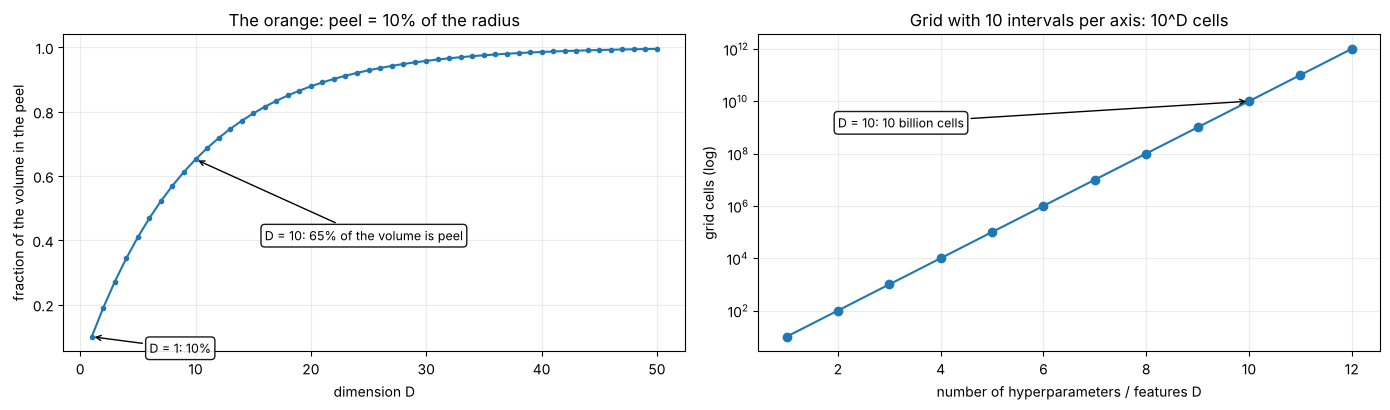

Number of polynomial features (without the constant column), as in the slide table:


,D = 2,D = 10,D = 100
degree 2,5,65,5150
degree 3,9,285,176850
degree 4,14,1000,4598125
degree 5,20,3002,96560645


In [23]:
from math import comb
Ds = np.arange(1, 51)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(Ds, 1 - 0.9 ** Ds, "o-", ms=3); ax[0].set_xlabel("dimension D"); ax[0].set_ylabel("fraction of the volume in the peel")
ax[0].set_title("The orange: peel = 10% of the radius")
annot(ax[0], f"D = 10: {1 - .9 ** 10:.0%} of the volume is peel", (10, 1 - .9 ** 10), (16, .4))
annot(ax[0], "D = 1: 10%", (1, .1), (6, .05))
ax[1].semilogy(Ds[:12], 10.0 ** Ds[:12], "o-"); ax[1].set_xlabel("number of hyperparameters / features D")
ax[1].set_ylabel("grid cells (log)"); ax[1].set_title("Grid with 10 intervals per axis: 10^D cells")
annot(ax[1], "D = 10: 10 billion cells", (10, 1e10), (2, 1e9))
plt.tight_layout(); plt.show()

tab = pd.DataFrame({f"D = {D}": [comb(D + g, g) - 1 for g in [2, 3, 4, 5]] for D in [2, 10, 100]}, index=[f"degree {g}" for g in [2, 3, 4, 5]])
print("Number of polynomial features (without the constant column), as in the slide table:")
tab

## B1. Feature selection `[course]`

**What it does**: chooses a **subset** $S$ of the $D$ original columns, $|S|=m$. The chosen columns stay **identical**, the others are discarded. Advantage: it stays **interpretable** (you know which measurements matter).

Problem: there are $2^D$ possible subsets. So you need two choices:
1. an **evaluation rule** (how do I score a feature or a subset?);
2. a **search strategy** (which subsets do I try?).

**Three families** (slide *Families of feature-selection methods*):

| Family | How it evaluates | Example | Pros | Cons |
|---|---|---|---|---|
| **Filter** | looks at the data, **without** training the final model | correlation with the target, Fisher score, variance | cheap | does not see interactions between features |
| **Wrapper** | trains the model on each subset and measures CV | forward selection with cross-validation | measures performance directly | **expensive**; the result depends on the chosen model |
| **Embedded** | selection happens **inside** training | **LASSO** (L1 regularisation) | no retraining for each subset | $\lambda$ must still be chosen by validation |

**LASSO** in short: $\min_\mathbf{w} L(\mathbf{w})+\lambda\sum_j|w_j|$. Unlike Ridge (L2, which shrinks the weights), the L1 penalty **sets some weights exactly to zero**: features with zero weight are discarded.

**Search strategies** (for filter and wrapper): exhaustive (all subsets), **forward** (start empty, add the best one), **backward** (start with all, remove the one that hurts least), floating (adds and removes), randomised.

**When to stop**: in the "CV score versus number of features" curve look for the **elbow**: with forward search it is the point where the curve starts to **plateau**.

The three plots below show one technique per family. The *wine* dataset (13 features, 3 classes) is my choice to keep computations quick; nb 09 uses digits.

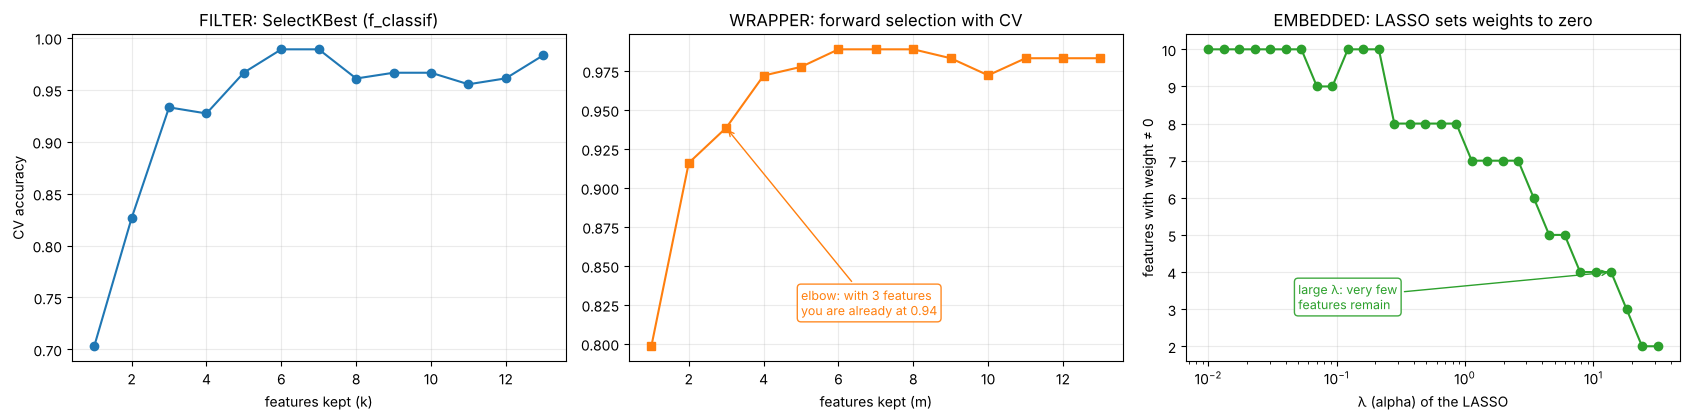

order of entry in forward selection: ['flavanoids', 'alcohol', 'proline', 'hue'] ...


In [24]:
from sklearn.datasets import load_wine, load_diabetes
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import Lasso
Xw, yw = load_wine(return_X_y=True)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

# FILTER: individual score (ANOVA F, similar to the Fisher score)
ks = range(1, 14)
filt = [cross_val_score(make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(max_iter=2000)), Xw, yw, cv=5).mean() for k in ks]

# WRAPPER: forward selection, at each step add the feature that raises CV the most
chosen, remaining, fwd = [], list(range(13)), []
for _ in range(13):
    scores = {j: cross_val_score(base, Xw[:, chosen + [j]], yw, cv=5).mean() for j in remaining}
    j_best = max(scores, key=scores.get); chosen.append(j_best); remaining.remove(j_best); fwd.append(scores[j_best])

# EMBEDDED: LASSO on regression (diabetes, 10 features): how many features keep a weight != 0
Xdb, ydb = load_diabetes(return_X_y=True); Xdb = StandardScaler().fit_transform(Xdb)
alphas = np.logspace(-2, 1.5, 30)
nz = [(Lasso(alpha=a, max_iter=10000).fit(Xdb, ydb).coef_ != 0).sum() for a in alphas]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].plot(ks, filt, "o-"); ax[0].set_xlabel("features kept (k)"); ax[0].set_ylabel("CV accuracy"); ax[0].set_title("FILTER: SelectKBest (f_classif)")
ax[1].plot(ks, fwd, "s-", c="tab:orange"); ax[1].set_xlabel("features kept (m)"); ax[1].set_title("WRAPPER: forward selection with CV")
annot(ax[1], f"elbow: with 3 features\nyou are already at {fwd[2]:.2f}", (3, fwd[2]), (5, fwd[0] + .02), "tab:orange")
ax[2].semilogx(alphas, nz, "o-", c="tab:green"); ax[2].set_xlabel("λ (alpha) of the LASSO"); ax[2].set_ylabel("features with weight ≠ 0")
ax[2].set_title("EMBEDDED: LASSO sets weights to zero")
annot(ax[2], "large λ: very few\nfeatures remain", (alphas[-4], nz[-4]), (0.05, 3), "tab:green")
plt.tight_layout(); plt.show()
print("order of entry in forward selection:", [load_wine().feature_names[j] for j in chosen[:4]], "...")

## B2-B4. Feature extraction: the three cards in brief `[course]`

It serves two purposes: **reducing noise/cost** (fewer columns) and **visualising**. In the template it is the `dim_reduction` step.

Key distinction `[course]`:
- **Feature selection**: you pick a subset of the existing columns (filter, wrapper).
- **Feature extraction**: you create **new** columns by combining the old ones (PCA, LDA, kernel PCA).

Dataset: sklearn's handwritten digits (64 pixels per image, 10 classes). Note `[mine]`: in notebook 09 the professor uses another digits dataset; this one is a toy dataset to get a plot straight away.

## B1. PCA `[course]`
- **Idea**: find the directions along which the data **vary the most** and project onto them.
- **What makes it special**: **linear** and **unsupervised**: it does not look at the labels `[course]`.
- **Strengths**: fast; `n_components` can be chosen as "how much variance I want to keep" (e.g. 0.95).
- **Weaknesses**: the direction of maximum variance **does not necessarily separate the classes**. Only linear transformations.
- **Knobs**: `n_components` (integer or fraction of explained variance).

## B2. LDA as a reduction `[course]`
- **What makes it special**: **supervised**. It looks for the directions that separate the classes, not those of maximum variance.
- **Strengths**: separates the classes well with few components.
- **Weaknesses**: at most $C-1$ components. Linear.

## B3. Kernel PCA `[course]`
- **What makes it special**: **non-linear** PCA (it uses a kernel, like the SVM). Useful when the structure is curved.
- **Weaknesses**: it is hard to measure the explained variance `[course]`. Costs more, has kernel knobs (`gamma`).

### Deep dive B2: PCA step by step (*Principal Component Analysis* slides)

**What does "principal component" mean?** It is a **new column**, a linear combination of the old ones, built along the direction in which the data **vary the most**. "Principal" because we order them from the most important.

**The five steps** (slide *PCA*, p. 38):
1. **Centre** the data: $\boldsymbol\mu=\frac1N\sum_n\mathbf{x}_n$, $\tilde{\mathbf{x}}_n=\mathbf{x}_n-\boldsymbol\mu$.
2. **Covariance**: $C=\frac1N\sum_n\tilde{\mathbf{x}}_n\tilde{\mathbf{x}}_n^\top$, a $D\times D$ matrix. On the diagonal the variances of the features, off the diagonal the covariances between pairs.
3. **Eigenvalues and eigenvectors** of $C$: $C\mathbf{u}_j=\lambda_j\mathbf{u}_j$, ordered $\lambda_1\ge\lambda_2\ge\dots\ge0$. The eigenvectors $\mathbf{u}_j$ are the **principal directions**, orthogonal to each other.
4. Keep the first $m$ in $W=[\mathbf{u}_1,\dots,\mathbf{u}_m]$, a $D\times m$ matrix.
5. **Transform**: $\mathbf{z}(\mathbf{x})=W^\top(\mathbf{x}-\boldsymbol\mu)$. The $z_j$ are the **principal components**.

**What the eigenvalues mean**: $\lambda_j$ is **the variance of the data along $\mathbf{u}_j$** ("explained variance"). A direction with $\lambda$ close to zero is one along which the data barely move: dropping it costs little.

**How many components to keep**: the fraction of explained variance is $\rho=\frac{\sum_{i\le m}\lambda_i}{\sum_{i\le D}\lambda_i}$. Rules of thumb: the smallest $m$ with $\rho\ge95\%$, or the elbow of the **scree plot**, or cross-validation (in the template: `n_components` in the grid).

**Another way to see it**: PCA finds the $m$-dimensional subspace that **reconstructs** the data best (minimum squared error), and the reconstruction error is exactly the discarded variance $\sum_{j>m}\lambda_j$.

**A worked example, with my own numbers** (slide p. 39 has a similar exercise with other numbers: that one is for you).
Let $\boldsymbol\mu=(0,0)$ and $C=\begin{pmatrix}2&1\\1&2\end{pmatrix}$.
- Eigenvalues: $\lambda_1=3$, $\lambda_2=1$. Eigenvectors: $\mathbf{u}_1=\frac{1}{\sqrt2}(1,1)$, $\mathbf{u}_2=\frac{1}{\sqrt2}(1,-1)$.
- Keeping only $\mathbf{u}_1$ retains $\rho=3/(3+1)=75\%$ of the variance.
- For $\mathbf{x}=(2,0)$: $z_1=\mathbf{u}_1^\top\mathbf{x}=2/\sqrt2\approx1.41$.

The cell below checks these numbers with numpy and shows the directions and the reconstruction of a digit.

**Limits** (slide *Limits of PCA*): it is **linear** (curved structures need many components) and it is **unsupervised**: it may throw away a low-variance direction that was exactly the one useful to separate the classes.

eigenvalues: [3. 1.] | u1 = [0.707 0.707] | variance kept with m=1: 0.75
z1 for x=(2,0): 1.414


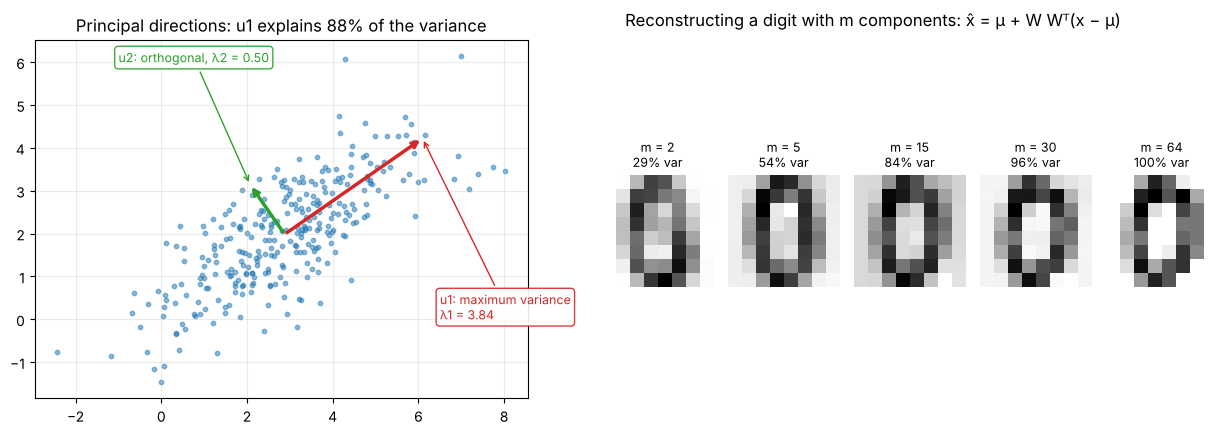

In [25]:
Cm = np.array([[2., 1.], [1., 2.]])
lam, U = np.linalg.eigh(Cm); order = np.argsort(lam)[::-1]; lam, U = lam[order], U[:, order]
print("eigenvalues:", lam, "| u1 =", U[:, 0].round(3), "| variance kept with m=1:", lam[0] / lam.sum())
print("z1 for x=(2,0):", round(abs(U[:, 0] @ np.array([2, 0])), 3))

rng = np.random.RandomState(1)
Xp = rng.multivariate_normal([3, 2], [[3, 1.6], [1.6, 1.5]], 300)
pca = PCA().fit(Xp); mu = pca.mean_
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(*Xp.T, s=10, alpha=.5)
for j, c in enumerate(["tab:red", "tab:green"]):
    v = pca.components_[j] * 2 * np.sqrt(pca.explained_variance_[j])
    ax[0].annotate("", xy=mu + v, xytext=mu, arrowprops=dict(arrowstyle="->", lw=2.5, color=c))
annot(ax[0], f"u1: maximum variance\nλ1 = {pca.explained_variance_[0]:.2f}", tuple(mu + pca.components_[0] * 2 * np.sqrt(pca.explained_variance_[0])), (6.5, 0), "tab:red")
annot(ax[0], f"u2: orthogonal, λ2 = {pca.explained_variance_[1]:.2f}", tuple(mu + pca.components_[1] * 2 * np.sqrt(pca.explained_variance_[1])), (-1, 6), "tab:green")
ax[0].set_aspect("equal"); ax[0].set_title(f"Principal directions: u1 explains {pca.explained_variance_ratio_[0]:.0%} of the variance")

dg2 = load_digits(); Xd2 = dg2.data; img = Xd2[0]
ax[1].axis("off"); ax[1].set_title("Reconstructing a digit with m components: x̂ = μ + W Wᵀ(x − μ)")
for k, m in enumerate([2, 5, 15, 30, 64]):
    p = PCA(n_components=m).fit(Xd2); rec = p.inverse_transform(p.transform(img[None]))[0]
    sub = fig.add_axes([0.53 + k * 0.09, 0.22, 0.08, 0.5]); sub.imshow(rec.reshape(8, 8), cmap="gray_r")
    sub.set_title(f"m = {m}\n{p.explained_variance_ratio_.sum():.0%} var", fontsize=9); sub.axis("off")
plt.show()

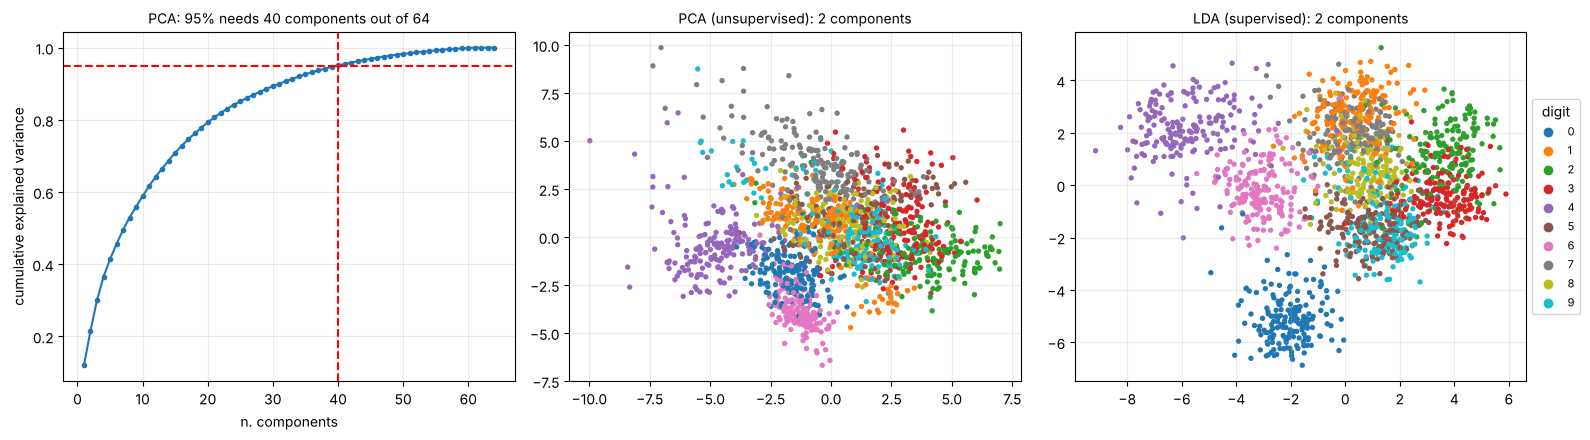

In [26]:
dg = load_digits()
Xd, yd = dg.data, dg.target
Xd = StandardScaler().fit_transform(Xd)

p = PCA().fit(Xd)
cum = np.cumsum(p.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)

pca2 = PCA(n_components=2).fit_transform(Xd)
lda2 = LinearDiscriminantAnalysis(n_components=2).fit(Xd, yd).transform(Xd)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].plot(range(1, 65), cum, "o-", ms=3); axs[0].axhline(.95, color="r", ls="--"); axs[0].axvline(k95, color="r", ls="--")
axs[0].set_xlabel("n. components"); axs[0].set_ylabel("cumulative explained variance")
axs[0].set_title(f"PCA: 95% needs {k95} components out of 64", fontsize=10)
for a, Z, t in [(axs[1], pca2, "PCA (unsupervised): 2 components"), (axs[2], lda2, "LDA (supervised): 2 components")]:
    sc = a.scatter(*Z.T, c=yd, cmap="tab10", s=8); a.set_title(t, fontsize=10)
axs[2].legend(*sc.legend_elements(), loc="center left", bbox_to_anchor=(1, .5), title="digit", fontsize=8)
plt.tight_layout(); plt.show()

**What to look at.** With the same 2 components LDA keeps some digits **more separated** (for example 0, 4 and 6 form clear groups), because it has seen the labels. PCA, which has not, mixes them more. With only 2 components neither separates all 10 digits.

Careful though: in this plot LDA was trained on **all** the data, just to draw. In real experiments the reduction goes **inside the pipeline**, trained on the training set only (otherwise there is **data leakage**, the open question about imputation in the template).

In [27]:
Xtr, Xte, ytr, yte = train_test_split(dg.data, dg.target, test_size=.3, stratify=dg.target, random_state=0)
cand = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "LogReg on 64 pixels": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "PCA(95%) + LogReg": make_pipeline(StandardScaler(), PCA(n_components=.95), LogisticRegression(max_iter=2000)),
    "LDA(9) + LogReg": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=9), LogisticRegression(max_iter=2000)),
}
rows = []
for nm, mod in cand.items():
    cv = cross_val_score(mod, Xtr, ytr, cv=5).mean()
    rows.append((nm, round(cv, 3), round(mod.fit(Xtr, ytr).score(Xte, yte), 3)))
pd.DataFrame(rows, columns=["pipeline", "CV acc (train)", "test acc"]).set_index("pipeline")

,CV acc (train),test acc
pipeline,,
dummy,0.101,0.102
LogReg on 64 pixels,0.964,0.972
PCA(95%) + LogReg,0.957,0.967
LDA(9) + LogReg,0.948,0.950


**What to look at.** The dummy gets about 0.1 (10 classes). The three real pipelines are all well above it. Reducing dimensions is not necessarily "more accurate": it often serves to **reduce complexity** while keeping performance. It is a choice to make with CV, not by eye.

### Deep dive B4: LDA as a reduction (*Linear Discriminant Analysis* slides, nb 09)

**The idea**: find the direction $\mathbf{w}$ along which, after projecting, **the class centres are far apart** and **each class is narrow**.

**Fisher's criterion (two classes)**:
$$J(\mathbf{w})=\frac{\big(\mathbf{w}^\top(\boldsymbol\mu_1-\boldsymbol\mu_2)\big)^2}{\mathbf{w}^\top S_W\mathbf{w}}$$
- Numerator: **distance between the centres** after projection, squared.
- Denominator: **width of the classes** along $\mathbf{w}$. $S_W=\sum_c\sum_{n:t_n=c}(\mathbf{x}_n-\boldsymbol\mu_c)(\mathbf{x}_n-\boldsymbol\mu_c)^\top$ is the *within-class scatter*.

In nb 09 the denominator is written $N_0\,\mathbf{w}^\top S_0\mathbf{w}+N_1\,\mathbf{w}^\top S_1\mathbf{w}$: it is the same thing, because $N_c S_c$ is exactly the scatter of class $c$.

**The solution has a formula** (slide *The two-class LDA direction*):
$$\mathbf{w}\propto S_W^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_2)$$
- $\boldsymbol\mu_1-\boldsymbol\mu_2$ is the direction joining the centres;
- $S_W^{-1}$ **corrects** it by taking into account the shape (tilt) of the clouds. That is why the LDA direction is not the one joining the centres.
- If $S_W$ is nearly singular it is regularised: $S_W+\delta I$ (like Ridge).

**More classes**: add the *between-class scatter* $S_B=\sum_c N_c(\boldsymbol\mu_c-\boldsymbol\mu)(\boldsymbol\mu_c-\boldsymbol\mu)^\top$ and maximise $\frac{\mathbf{w}^\top S_B\mathbf{w}}{\mathbf{w}^\top S_W\mathbf{w}}$. You get at most $\min\{D,\,C-1\}$ directions (a *generalized eigenproblem*). With 10 digits: at most 9 components, which is why nb 09 uses `n_components=9`.

Note: in the text I extracted from slide p. 53 the mean $\boldsymbol\mu_c$ is written without $\frac{1}{N_c}$; nb 09 has it. Check on the slide: I think it is a typo.

**PCA versus LDA, the key figure** (slide *PCA vs LDA*): below, two elongated, parallel classes. PCA picks the direction of **maximum total variance**, which runs along the clouds and **mixes** them. LDA picks the one that **separates** them.

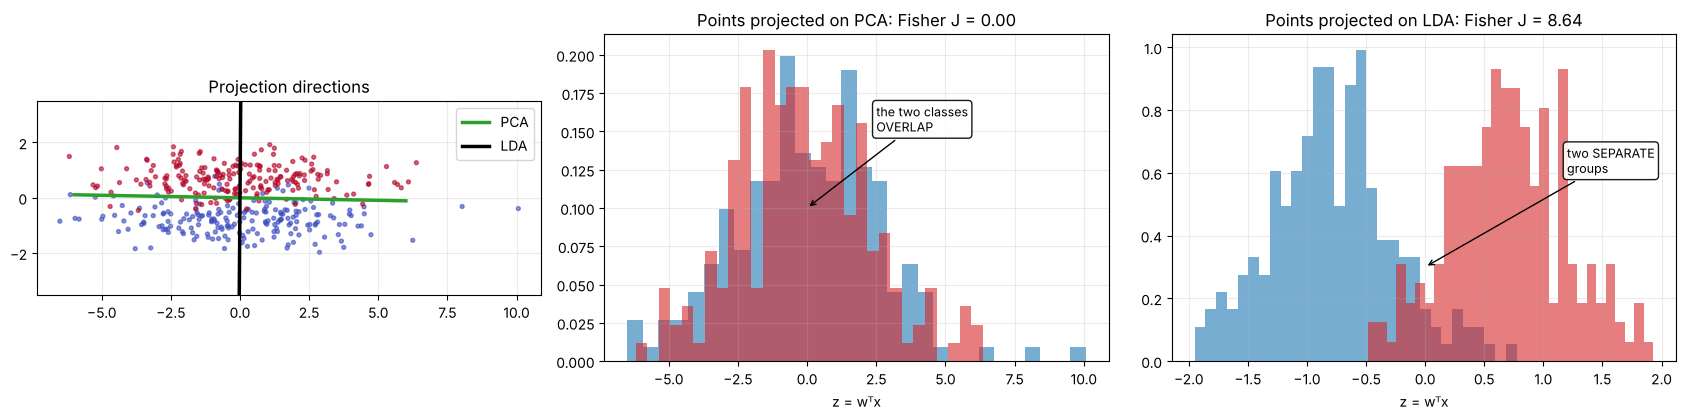

PCA direction: [ 1.   -0.02] | LDA direction: [0.01 1.  ]


In [28]:
rng = np.random.RandomState(2)
cov = [[6, 0], [0, 0.25]]
X0 = rng.multivariate_normal([0, -0.8], cov, 200); X1 = rng.multivariate_normal([0, 0.8], cov, 200)
Xpl = np.r_[X0, X1]; ypl = np.r_[np.zeros(200), np.ones(200)]
w_pca = PCA(1).fit(Xpl).components_[0]
mu0, mu1 = X0.mean(0), X1.mean(0)
SW = (X0 - mu0).T @ (X0 - mu0) + (X1 - mu1).T @ (X1 - mu1)
w_lda = np.linalg.solve(SW, mu1 - mu0); w_lda /= np.linalg.norm(w_lda)
J = lambda w: (w @ (mu1 - mu0)) ** 2 / (w @ (SW / len(Xpl)) @ w)   # S_W divided by N: same direction, readable numbers

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].scatter(*Xpl.T, c=ypl, cmap=CMAP, s=8, alpha=.6)
for w, c, nm in [(w_pca, "tab:green", "PCA"), (w_lda, "k", "LDA")]:
    ax[0].plot([-6 * w[0], 6 * w[0]], [-6 * w[1], 6 * w[1]], c=c, lw=2.5, label=nm)
ax[0].set_aspect("equal"); ax[0].set_ylim(-3.5, 3.5); ax[0].legend(); ax[0].set_title("Projection directions")
for a, w, nm in [(ax[1], w_pca, "PCA"), (ax[2], w_lda, "LDA")]:
    z = Xpl @ w
    a.hist(z[ypl == 0], 30, alpha=.6, color="tab:blue", density=True); a.hist(z[ypl == 1], 30, alpha=.6, color="tab:red", density=True)
    a.set_title(f"Points projected on {nm}: Fisher J = {J(w):.2f}"); a.set_xlabel("z = wᵀx")
annot(ax[1], "the two classes\nOVERLAP", (0, .1), (2.5, .15))
annot(ax[2], "two SEPARATE\ngroups", (0, .3), (1.2, .6))
plt.tight_layout(); plt.show()
print("PCA direction:", w_pca.round(2), "| LDA direction:", w_lda.round(2))

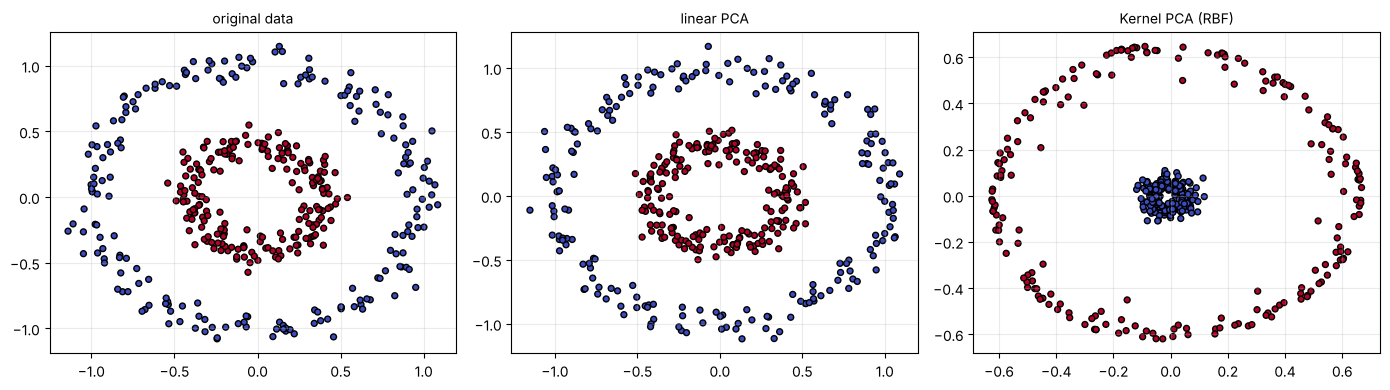

In [29]:
Xc, yc = make_circles(400, noise=0.07, factor=0.4, random_state=0)
Zl = PCA(n_components=2).fit_transform(Xc)
Zk = KernelPCA(n_components=2, kernel="rbf", gamma=8).fit_transform(Xc)
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for a, Z, t in [(axs[0], Xc, "original data"), (axs[1], Zl, "linear PCA"), (axs[2], Zk, "Kernel PCA (RBF)")]:
    a.scatter(*Z.T, c=yc, cmap=CMAP, edgecolor="k", s=18); a.set_title(t, fontsize=10)
plt.tight_layout(); plt.show()

**What to look at.** Linear PCA is just a **rotation**: the circles stay one inside the other. Kernel PCA really changes the structure (here it "turns the circles inside out": the outer one ends up squeezed in the centre), but in these **2** components the classes are **not** yet separable by a straight line. *Correction to yesterday: I had written the opposite.* In deep dive B3 you see that the third component is needed. It is the same kernel trick as in the SVM, applied to PCA.

### In your own words (2)
Explain to a classmate **why PCA may *not* help a classifier** while LDA usually does (think "variance" versus "separation between classes").

### Deep dive B3: Kernel PCA (*Kernel PCA* slides)

**Idea**: do PCA in the feature space $\phi(\mathbf{x})$ of a kernel, without building it (kernel trick, as in the SVM).

**How it is computed, roughly** (slides pp. 44-48):
1. Build the **Gram matrix** $K_{nm}=k(\mathbf{x}_n,\mathbf{x}_m)$, of size $N\times N$.
2. **Centre it**: $\bar K = HKH$ with $H=I_N-\frac1N\mathbf{1}\mathbf{1}^\top$. Needed because centring the inputs does not centre the features.
3. Find the eigenvalues $\eta_1\ge\dots$ and eigenvectors $\mathbf{v}_j$ of $\bar K$, keep the first $m$.
4. The components of the training points are $\mathbf{z}_j=\sqrt{\eta_j}\,\mathbf{v}_j$.
5. A new point needs its similarities with **all** training points.

**Limits**: you must store an $N\times N$ matrix and the decomposition costs $O(N^3)$; transforming a new point requires comparing it with the whole training set; and it is still **unsupervised**. Also, there is no simple way to measure the explained variance (nb 09): `n_components` and `gamma` are chosen with CV.

**A lesson from the plot below.** On the circles, with $\gamma=2$, the first two components do **not** separate the classes. It is the **third** that separates them, on its own. Kernel PCA orders components by variance, not by usefulness for the task: this is exactly the "unsupervised" limit. That is why `n_components` must be chosen with cross-validation (third panel).

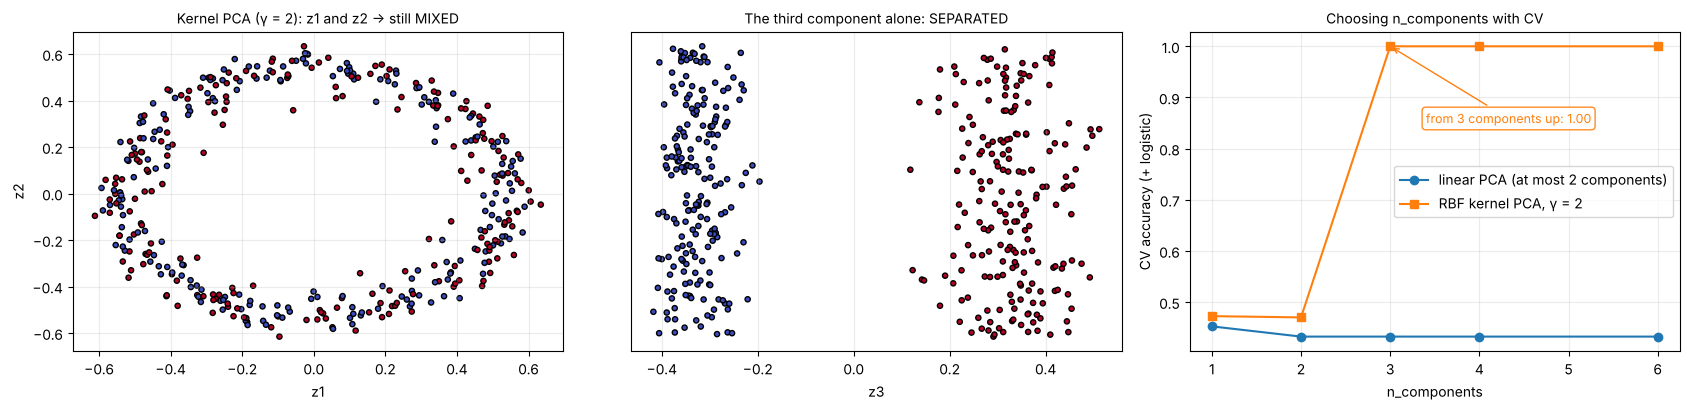

In [30]:
Xc3, yc3 = make_circles(400, noise=0.07, factor=0.4, random_state=0)
Z3 = KernelPCA(n_components=3, kernel="rbf", gamma=2).fit_transform(Xc3)
ms = [1, 2, 3, 4, 6]
acc_k = [cross_val_score(make_pipeline(KernelPCA(m, kernel="rbf", gamma=2), StandardScaler(), LogisticRegression()), Xc3, yc3, cv=5).mean() for m in ms]
acc_l = [cross_val_score(make_pipeline(PCA(min(m, 2)), LogisticRegression()), Xc3, yc3, cv=5).mean() for m in ms]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].scatter(Z3[:, 0], Z3[:, 1], c=yc3, cmap=CMAP, edgecolor="k", s=14); ax[0].set_xlabel("z1"); ax[0].set_ylabel("z2")
ax[0].set_title("Kernel PCA (γ = 2): z1 and z2 → still MIXED", fontsize=10)
ax[1].scatter(Z3[:, 2], np.random.RandomState(0).uniform(-1, 1, len(yc3)), c=yc3, cmap=CMAP, edgecolor="k", s=14)
ax[1].set_xlabel("z3"); ax[1].set_yticks([]); ax[1].set_title("The third component alone: SEPARATED", fontsize=10)
ax[2].plot(ms, acc_l, "o-", label="linear PCA (at most 2 components)"); ax[2].plot(ms, acc_k, "s-", label="RBF kernel PCA, γ = 2")
ax[2].set_xlabel("n_components"); ax[2].set_ylabel("CV accuracy (+ logistic)"); ax[2].legend(loc="center right"); ax[2].set_title("Choosing n_components with CV", fontsize=10)
annot(ax[2], "from 3 components up: 1.00", (3, acc_k[2]), (3.4, .85), "tab:orange")
plt.tight_layout(); plt.show()

*(write your answer here)*

# Part C. Regression `[course]` (nb 05 and slides)

Here the answer is a **number**, not a class. The underlying question does not change: *how complex should the model be?*

## C1. Linear regression (OLS)
- **Idea**: the line $\hat t = \mathbf{w}^\top\mathbf{x}$ that minimises the sum of squared errors (RSS).
- **What makes it special**: it has a **closed-form solution** (pseudo-inverse), or you use gradient descent. It is the same as Adaline, but on continuous values.
- **Strengths**: simple, interpretable.
- **Weaknesses**: if the relationship is curved it **underfits**; with collinear features or more features than samples the matrix is not invertible (**rank deficiency**).

## C2. Ridge (L2 regularisation) `[course]`
- **What makes it special**: adds $\lambda\|\mathbf{w}\|^2$ to the loss: penalises large weights. $\lambda I+\Phi^\top\Phi$ is **always invertible**.
- **Strengths**: curbs overfitting, solves rank deficiency.
- **Knobs**: `alpha` ($\lambda$): large = small weights, simpler model.

## C3. Polynomials: not a model, a trick
`PolynomialFeatures` adds $x^2, x^3,\dots$ as **new columns**; the model remains a regression that is **linear in the weights**. The degree is a complexity hyperparameter.

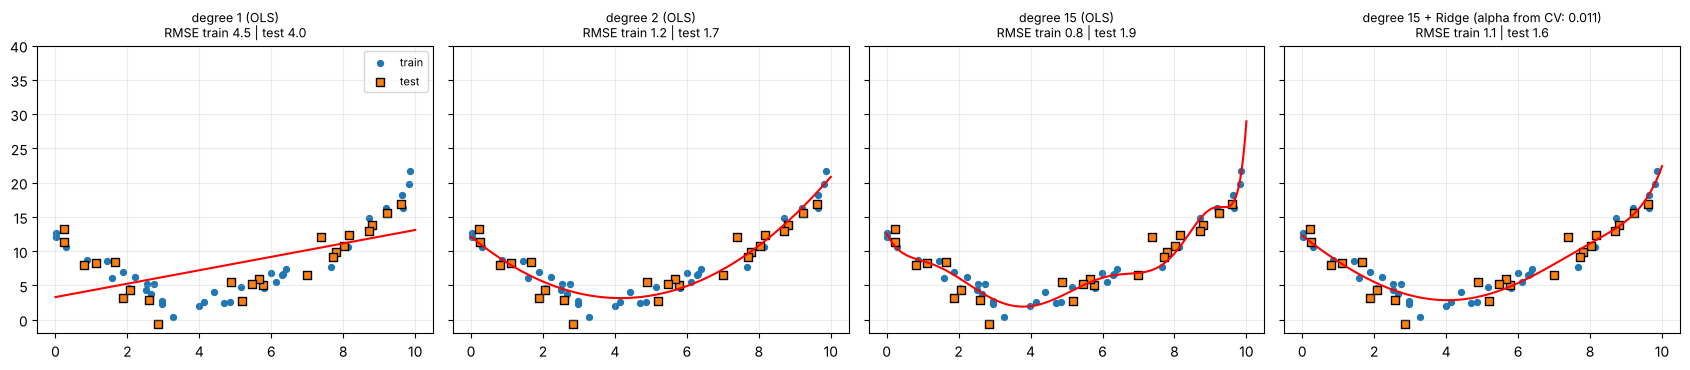

In [31]:
rng = np.random.RandomState(5)
x = rng.uniform(0, 10, 60)
t = 3 + 0.5 * (x - 4) ** 2 + rng.normal(0, 1.5, 60)
Xr = x.reshape(-1, 1)
Xrtr, Xrte, trtr, trte = train_test_split(Xr, t, test_size=.4, random_state=0)
xg = np.linspace(0, 10, 300).reshape(-1, 1)

mods = {
    "degree 1 (OLS)": make_pipeline(StandardScaler(), LinearRegression()),
    "degree 2 (OLS)": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "degree 15 (OLS)": make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), LinearRegression()),
    "degree 15 + Ridge": make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 2, 20), cv=5)),
}
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
for a, (nm, mod) in zip(axs, mods.items()):
    mod.fit(Xrtr, trtr)
    a.scatter(Xrtr, trtr, s=18, label="train"); a.scatter(Xrte, trte, s=40, marker="s", edgecolor="k", label="test")
    a.plot(xg, mod.predict(xg), "r"); a.set_ylim(-2, 40)
    extra = f" (alpha from CV: {mod[-1].alpha_:.2g})" if "Ridge" in nm else ""
    a.set_title(f"{nm}{extra}\nRMSE train {rmse(trtr, mod.predict(Xrtr)):.1f} | test {rmse(trte, mod.predict(Xrte)):.1f}", fontsize=9)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to look at.** Degree 1: high error on train **and** test (underfitting, *high bias*). Degree 2: right, because the data come from a parabola. Degree 15: the training error goes down further, but the test **does not improve** over degree 2, and the curve wiggles and "explodes" near x=10 (overfitting, *high variance*). Degree 15 with Ridge: `alpha` is chosen with cross-validation **on the training set only** and the curve becomes smooth again; look at the numbers in the title to see what happens to train and test.

Note: the test set has few points (24), so look at the **shape** of the curves more than the decimals. And remember: `alpha` is chosen with CV, **never by looking at the test set**.

### Deep dive: evaluating a regression (nb 05, nb 06, model selection slides)

**RMSE**: $\sqrt{\frac1N\sum_n(t_n-\hat t_n)^2}$, in the same unit as the target ("I'm off by about X on average").

**R²** (*model selection* slides): $R^2=1-\frac{RSS}{TSS}$, with $RSS=\sum_n(t_n-\hat t_n)^2$ and $TSS=\sum_n(t_n-\bar t)^2$.
- It is a comparison with the **trivial model that always predicts the mean** $\bar t$ (the regression "dummy"). `r2_score(y_test, y_pred)` computes the mean internally.
- $R^2=1$: perfect. $R^2=0$: as good as the mean. $R^2<0$: **worse** than the mean.

**Residual plot** (nb 05): prediction on the x axis, residual $t-\hat t$ on the y axis. If the model is right the points are a random cloud around 0. If you see a **shape** (for example a U), the model is missing some structure: typically a non-linear term is needed.

**k-NN regression** (nb 05, slide *Nearest-neighbor regression*): $\hat t(\mathbf{x})=\frac1K\sum_{n\in N_K(\mathbf{x})}t_n$, the mean of the neighbours' targets. With `weights='distance'` it is a weighted mean. $K=1$ chases every point, a large $K$ flattens the curve.

The kernel slides also have **kernel ridge regression** and **Gaussian-weighted averaging** (Nadaraya-Watson): same idea as averaging the neighbours, but weighted with a kernel.

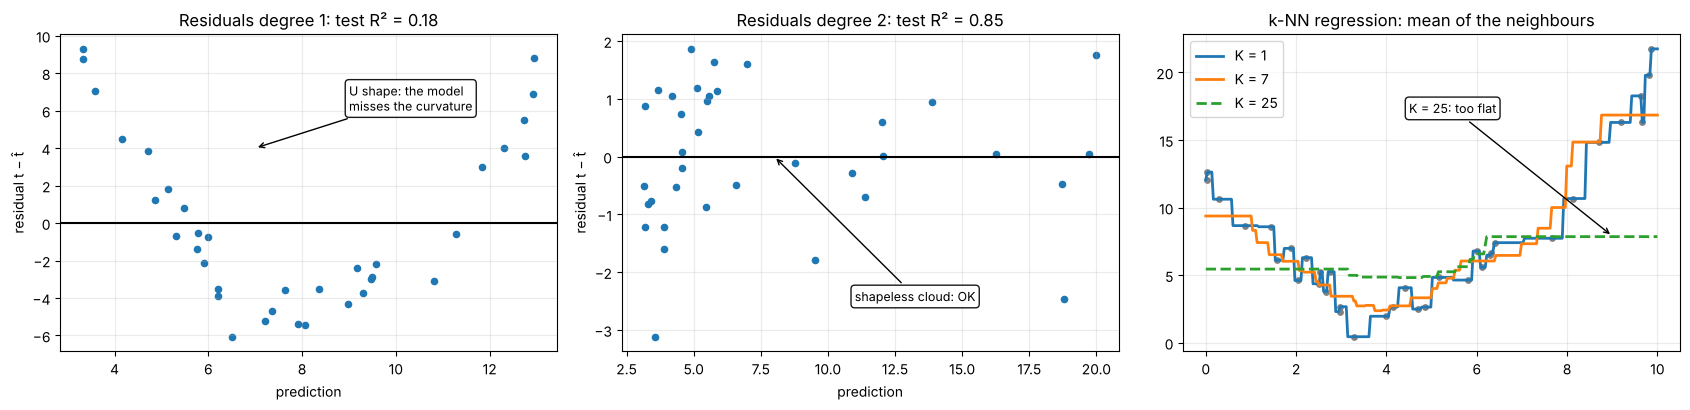

In [32]:
from sklearn.metrics import r2_score
from sklearn.neighbors import KNeighborsRegressor
m1 = make_pipeline(StandardScaler(), LinearRegression()).fit(Xrtr, trtr)
m2 = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()).fit(Xrtr, trtr)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a, m, nm in [(ax[0], m1, "degree 1"), (ax[1], m2, "degree 2")]:
    pr = m.predict(Xrtr); a.scatter(pr, trtr - pr, s=20); a.axhline(0, c="k")
    a.set_xlabel("prediction"); a.set_ylabel("residual t − t̂")
    a.set_title(f"Residuals {nm}: test R² = {r2_score(trte, m.predict(Xrte)):.2f}")
annot(ax[0], "U shape: the model\nmisses the curvature", (7, 4), (9, 6))
annot(ax[1], "shapeless cloud: OK", (8, 0), (11, -2.5))
for K, st in [(1, "-"), (7, "-"), (25, "--")]:
    ax[2].plot(xg, KNeighborsRegressor(K).fit(Xrtr, trtr).predict(xg), st, lw=2, label=f"K = {K}")
ax[2].scatter(Xrtr, trtr, s=15, c="gray"); ax[2].legend(); ax[2].set_title("k-NN regression: mean of the neighbours")
annot(ax[2], "K = 25: too flat", (9, 7.9), (4.5, 17))
plt.tight_layout(); plt.show()

# Part D0. Measuring a classifier `[course]` (nb 06, *model selection* slides)

**Confusion matrix** (two classes, "positive" = the class you want to find):

| | predicted positive | predicted negative |
|---|---|---|
| **actually positive** | **TP** (caught!) | **FN** (missed) |
| **actually negative** | **FP** (false alarm) | **TN** (ok) |

- **Accuracy** $=\frac{TP+TN}{\text{all}}$: misleading with imbalanced classes.
- **Precision** $=\frac{TP}{TP+FP}$: "when I say positive, how often am I right?"
- **Recall** $=\frac{TP}{TP+FN}$: "of the real positives, how many do I find?"
- **F1** $=2\frac{P\cdot R}{P+R}$: harmonic mean, high only if **both** are high. It is the template's metric.

In sklearn: `precision_score(y_true, y_pred, pos_label=1)` and similar; `confusion_matrix(y_true, y_pred)`.

**Precision-recall curve** (nb 06): moving the classifier's threshold gives many (P, R) pairs. Used when classes are imbalanced.

**Imbalanced classes** (nb 06, *Unbalanced classes*): with 90% negatives, the dummy gets accuracy 0.90 and F1 = 0. Remedies: look at F1 or the PR curve instead of accuracy, `stratify=y` in the split, `class_weight='balanced'` (weighs errors on the rare class more), or a **sampler** (in the template: `imbalanced-learn`).

**Holdout versus K-fold** (nb 06): holdout uses **one** validation set (fast, but the result depends on the split); K-fold repeats $K$ times with different folds and averages (more stable). The test set is used **only once**, at the end.

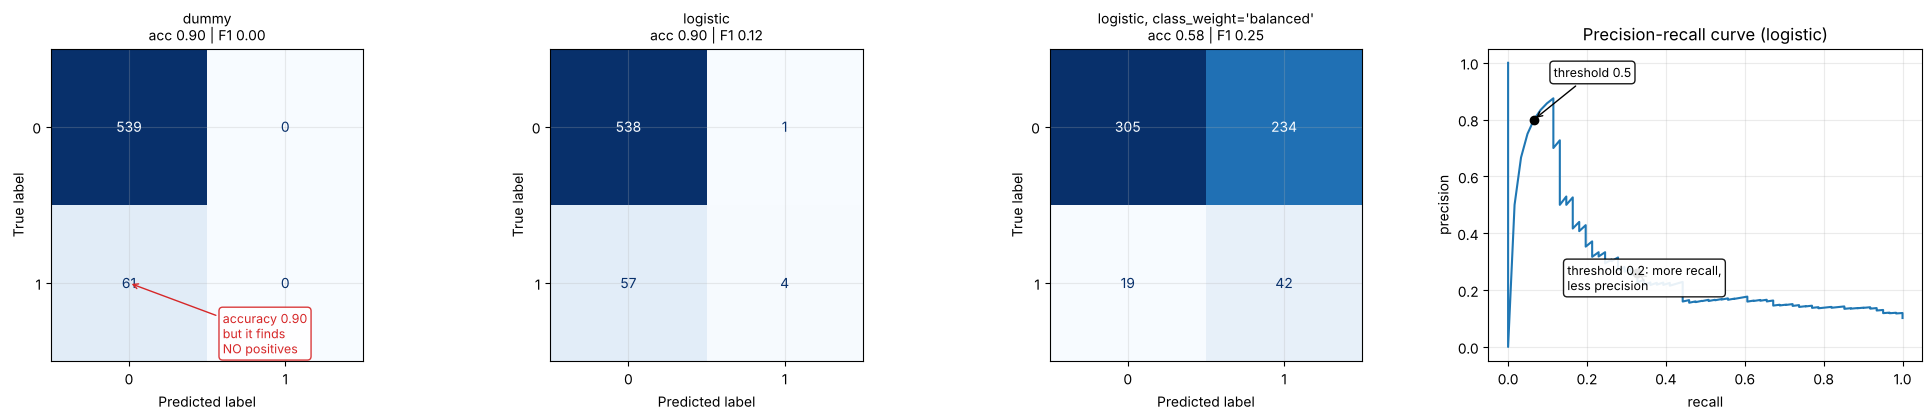

In [33]:
from sklearn.datasets import make_classification
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, precision_recall_curve, accuracy_score
Xu, yu = make_classification(2000, n_features=6, n_informative=3, weights=[0.9, 0.1], class_sep=0.8, random_state=0)
Xutr, Xute, yutr, yute = train_test_split(Xu, yu, test_size=.3, stratify=yu, random_state=0)
mods = {"dummy": DummyClassifier(strategy="most_frequent"),
        "logistic": make_pipeline(StandardScaler(), LogisticRegression()),
        "logistic, class_weight='balanced'": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
for a, (nm, m) in zip(ax, mods.items()):
    pr = m.fit(Xutr, yutr).predict(Xute)
    ConfusionMatrixDisplay.from_predictions(yute, pr, ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{nm}\nacc {accuracy_score(yute, pr):.2f} | F1 {f1_score(yute, pr, zero_division=0):.2f}", fontsize=10)
annot(ax[0], "accuracy 0.90\nbut it finds\nNO positives", (0, 1), (0.6, 1.45), "tab:red")
lr_u = mods["logistic"]; P, R, T = precision_recall_curve(yute, lr_u.predict_proba(Xute)[:, 1])
ax[3].plot(R, P); ax[3].set_xlabel("recall"); ax[3].set_ylabel("precision"); ax[3].set_title("Precision-recall curve (logistic)")
i5 = np.argmin(abs(T - 0.5)); i2 = np.argmin(abs(T - 0.2))
ax[3].scatter([R[i5], R[i2]], [P[i5], P[i2]], c="k", zorder=3)
annot(ax[3], "threshold 0.5", (R[i5], P[i5]), (R[i5] + .05, P[i5] + .15))
annot(ax[3], "threshold 0.2: more recall,\nless precision", (R[i2], P[i2]), (.15, .2))
plt.tight_layout(); plt.show()

**What to look at.** The dummy has accuracy 0.90 and F1 0: it finds no positives. The plain logistic has the same accuracy but finds only 4 positives out of 61. With `class_weight='balanced'` accuracy **drops** to 0.58, but the positives found rise to 42 out of 61 and F1 rises from 0.12 to 0.25, at the cost of 234 false alarms. Which is better depends on how much a false alarm costs you compared with a missed positive: it is a project decision to justify at the oral exam.

# Part D. The "knobs" and how to choose them `[course]` (nb 06 and slides)

Every model has a complexity knob. The thread that connects them:

| Model | Knob | Too "low" | Too "high" |
|---|---|---|---|
| Logistic | `C` | too much regularisation (underfit) | too little (overfit) |
| RBF SVM | `gamma`, `C` | boundary too straight | islands around points |
| k-NN | `K` | large `K`: too smooth | `K=1`: learns by heart |
| Polynomial | degree | line on curved data | wiggles between points |
| Ridge | `alpha` | free weights (overfit) | weights near zero (underfit) |

You choose with a **validation curve** (one knob) or **GridSearchCV / RandomizedSearchCV** (several knobs together), inside CV. To honestly estimate the performance of the whole thing you use **nested CV**.

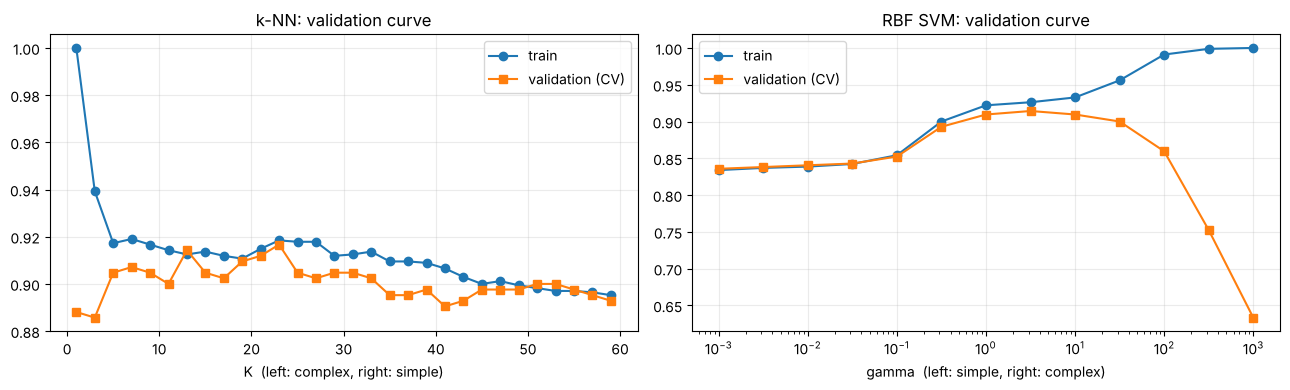

best K for k-NN: 23 | best gamma for SVM: 3.1622776601683795


In [34]:
Xm, ym = make_moons(600, noise=0.3, random_state=1)
Xmtr, Xmte, ymtr, ymte = train_test_split(Xm, ym, test_size=.3, stratify=ym, random_state=0)

ks = np.arange(1, 60, 2)
tr, va = validation_curve(make_pipeline(StandardScaler(), KNeighborsClassifier()), Xmtr, ymtr,
                          param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=5)
gs = np.logspace(-3, 3, 13)
tr2, va2 = validation_curve(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)), Xmtr, ymtr,
                            param_name="svc__gamma", param_range=gs, cv=5)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(ks, tr.mean(1), "o-", label="train"); axs[0].plot(ks, va.mean(1), "s-", label="validation (CV)")
axs[0].set_xlabel("K  (left: complex, right: simple)"); axs[0].set_title("k-NN: validation curve"); axs[0].legend()
axs[1].semilogx(gs, tr2.mean(1), "o-", label="train"); axs[1].semilogx(gs, va2.mean(1), "s-", label="validation (CV)")
axs[1].set_xlabel("gamma  (left: simple, right: complex)"); axs[1].set_title("RBF SVM: validation curve"); axs[1].legend()
plt.tight_layout(); plt.show()
print("best K for k-NN:", int(ks[va.mean(1).argmax()]), "| best gamma for SVM:", float(gs[va2.mean(1).argmax()]))

**What to look at.** In both plots the **train** curve rises with complexity (to the left for K, to the right for gamma). In the **SVM** the validation curve rises and then **collapses**: the point where it detaches from the train curve is overfitting. In **k-NN** the effect is much smaller and noisier (differences of 1-3 percentage points): with `K=1` train is 1.00 but validation is among the lowest. Pick the knob where validation is highest, **not** where train is highest.

### In your own words (3)
With an example of your choice (k-NN or SVM), explain to a classmate **what it means** that the validation curve "goes down" while train goes up, and what you would do in the project.

### GridSearchCV and nested CV in code (nb 06, slide *Nested cross-validation*, template)

- **GridSearchCV**: tries every combination in the grid, runs K-fold for each and keeps the best. Parameter names in a pipeline are `stepname__parameter`.
- **Careful**: the best score found by the grid search is **optimistic**, because you chose exactly the combination that did best on those folds (*selection bias*).
- **Nested CV**: an **outer** CV evaluates the whole "grid search + model" procedure. The outer score is an honest estimate. It is what the template does with `cross_val_score(GridSearchCV(...))` (or `RandomizedSearchCV`).

In [35]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 1, 10]}
gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="f1")
gs.fit(Xmtr, ymtr)
print("best parameters:", gs.best_params_, "| inner F1 (optimistic):", round(gs.best_score_, 3))
outer = cross_val_score(gs, Xmtr, ymtr, cv=StratifiedKFold(5, shuffle=True, random_state=1), scoring="f1")
print("nested CV, outer F1:", outer.round(3), "mean", round(outer.mean(), 3))
print("fits: 16 combinations × 5 inner folds × 5 outer folds = 400 (+ the refits)")

best parameters: {'svc__C': 1, 'svc__gamma': 1} | inner F1 (optimistic): 0.915


nested CV, outer F1: [0.875 0.932 0.916 0.92  0.876] mean 0.904
fits: 16 combinations × 5 inner folds × 5 outer folds = 400 (+ the refits)


*(write your answer here)*

# Part E. Preprocessing: the first step of every project `[course]` (nb 01)

In the project it comes **before** everything else; I put it here at the end so as not to break up the review of the models.

| Problem | sklearn solution | Notes |
|---|---|---|
| **Missing values** | `SimpleImputer(strategy="mean" / "median" / "most_frequent")` | or drop rows or columns; the median is robust to outliers |
| **Nominal categories** (e.g. city) | `OneHotEncoder` | one 0/1 column per category; `handle_unknown="ignore"` for categories never seen |
| **Ordinal categories** (e.g. S < M < L) | `OrdinalEncoder` with the right order | 0, 1, 2 make sense only if the order exists |
| **Discretisation** (binning) | `KBinsDiscretizer` | turns a number into bands; loses information |
| **Different scales** | `StandardScaler` (mean 0, std 1) or `MinMaxScaler` ([0, 1]) | essential for k-NN, SVM, gradient descent, PCA |
| **Columns of different types** | `ColumnTransformer` + `Pipeline` | each group of columns gets its own treatment |

**The golden rule**: every transformation is **fitted on the training set only** (`fit`) and **applied** to the test set (`transform`). Inside a `Pipeline` this happens automatically, even inside cross-validation. If you impute the mean computed on the **whole** dataset, information from the test set leaks into training: that is **data leakage** (the open question about the template).

The plot below shows why scaling matters: k-NN with unscaled features listens almost only to the feature with the largest numbers.

BEFORE:


,age,income,city
0,22.0,18000.0,Pavia
1,NaN,32000.0,Milan
2,35.0,NaN,NaN
3,58.0,61000.0,Pavia
4,41.0,45000.0,Lodi


AFTER the ColumnTransformer:


,num__age,num__income,cat__city_Lodi,cat__city_Milan,cat__city_Pavia
0,-1.45,-1.47,0.0,0.0,1.0
1,-0.07,-0.49,0.0,1.0,0.0
2,-0.33,-0.03,0.0,0.0,1.0
3,1.66,1.55,0.0,0.0,1.0
4,0.19,0.43,1.0,0.0,0.0


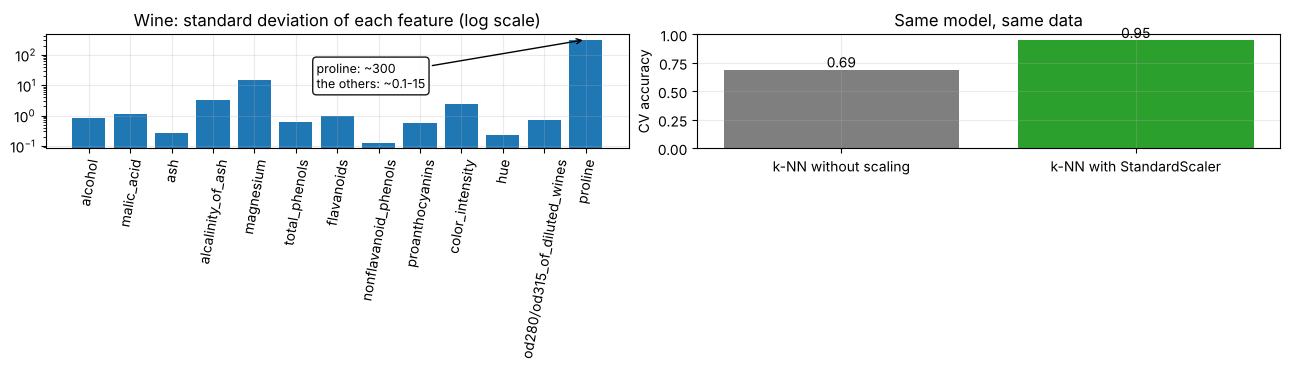

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
df = pd.DataFrame({"age": [22, np.nan, 35, 58, 41], "income": [18000, 32000, np.nan, 61000, 45000],
                   "city": ["Pavia", "Milan", np.nan, "Pavia", "Lodi"]})
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), ["age", "income"]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), ["city"]),
])
print("BEFORE:"); display(df)
print("AFTER the ColumnTransformer:")
display(pd.DataFrame(prep.fit_transform(df), columns=prep.get_feature_names_out()).round(2))

Xw2, yw2 = load_wine(return_X_y=True)
without = cross_val_score(KNeighborsClassifier(5), Xw2, yw2, cv=5).mean()
with_sc = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), Xw2, yw2, cv=5).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(load_wine().feature_names, Xw2.std(0)); ax[0].set_yscale("log"); ax[0].tick_params(axis="x", rotation=80)
ax[0].set_title("Wine: standard deviation of each feature (log scale)")
annot(ax[0], "proline: ~300\nthe others: ~0.1-15", (12, Xw2.std(0)[12]), (5.5, 8))
ax[1].bar(["k-NN without scaling", "k-NN with StandardScaler"], [without, with_sc], color=["tab:gray", "tab:green"])
ax[1].set_ylim(0, 1); ax[1].set_ylabel("CV accuracy")
for i, v in enumerate([without, with_sc]): ax[1].text(i, v + .02, f"{v:.2f}", ha="center")
ax[1].set_title("Same model, same data")
plt.tight_layout(); plt.show()

# Final mind map

| Model / technique | Type | What makes it special (one line) | Strengths | Weaknesses | Main knob |
|---|---|---|---|---|---|
| Dummy | baseline | ignores the features | minimum yardstick | not a candidate | strategy |
| Perceptron | linear | threshold error (0/1) | converges if separable | oscillates otherwise | eta0, max_iter |
| Adaline | linear | squared error on $z$ | smooth cost: GD or closed form | penalises "too correct" points | $\eta$, epochs |
| Logistic | linear | sigmoid and log-loss: probabilities | interpretable, adjustable threshold | linear boundary | C |
| OvR / OvO / softmax | multiclass | how to extend to $K$ classes | — | OvO: $K(K-1)/2$ models | — |
| Feature mapping | trick | new columns → curved boundary | simple | columns explode | degree |
| Linear SVM | linear | maximum margin, support vectors | unique choice among infinite lines | no direct probabilities | C |
| RBF SVM | non-linear (kernel) | sum of similarities with the support vectors | flexible, adaptive centres | slow, sensitive | gamma, C |
| k-NN | non-parametric | no training, neighbours vote | simple, any distance | memory, slow prediction, suffers from dimension | K, weights, metric |
| LDA (classif.) | linear, generative | Gaussian clouds with the same shape | closed form, multiclass | Gaussian assumption | — |
| Filter / wrapper / LASSO | selection | keeps **some original columns** | interpretable | wrapper is expensive | k, m, $\lambda$ |
| PCA | extraction, unsup. | directions of maximum variance | fast, chosen by variance | may drop what separates | n_components |
| Kernel PCA | extraction, unsup. | PCA with a kernel | curved structures | $N\times N$, $O(N^3)$ | kernel, gamma |
| LDA (reduction) | extraction, **sup.** | maximises the Fisher score | few useful components | at most $C-1$ components | n_components |
| OLS / Ridge / LASSO | regression | least squares (+ L2 / L1) | simple; L1 selects | linear in the weights | alpha |
| k-NN regression | regression | mean of the neighbours | any curve | as k-NN | K |

**Three questions to find your way** `[mine]`:
1. Should the boundary be **straight or curved**? (linear versus kernel / k-NN / feature mapping)
2. Do I need **probabilities**? (logistic, LDA)
3. How many **samples** and how many **dimensions** do I have? (k-NN and RBF SVM suffer with many samples or dimensions; selection and extraction help)

And always: **cross-validation decides**, not the eye.

# Still missing (course programme, not yet in the notebooks)

**Decision Tree**, **ensembles** (bagging, Random Forest, boosting/XGBoost), **clustering** (k-means, hierarchical, density-based). The **Random Forest** is also needed for the template. The template's **sampler** (`imbalanced-learn`) is in no notebook: ask about it or study it separately.

# Free space for your notes

*(write here)*